# Predicting fields while tracking a subspace
A modal basis gives one prediction. A subspace distribution also describes its direction-dependent uncertainty. The main figures study real **n=8, k=3** calibration with known inputs, time-varying states, and repeated noise realizations. The 64-sensor passive reconstruction experiment remains in the supplementary comparisons.

The central distinction is between an error bound for the modal estimate and a credible region under a maintained distribution. They are different objects. Taking G=I can give a useful modal bound under slow residual motion while its nominal credible region is miscalibrated. Figures use larger canvases, TeX, and editable 300-dpi defaults.

Every figure is now constructed by ordinary Matplotlib statements in its own code cell. The cell exposes `DPI`, `FIGSIZE`, labels, styles and `fig.savefig(...)`; there are no image-display or hidden rendering wrappers. The arrays are the original preserved historical experiments. Running this notebook reads those verified tables without simulating new observations or refitting anything. Custom PDF exports go to `results/notebook_exports/02_field/`, leaving the published data and figures intact. The supplied canvas sizes preserve the historical layouts and can be changed independently per cell.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from scipy.stats import t as student_t
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LogNorm
from matplotlib.lines import Line2D

ROOT = Path.cwd() if (Path.cwd() / 'lib').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from lib.notebook_field_data import load_field_data, field_input_hashes
# These helpers compute numerical summaries only; all Matplotlib calls are below.
from lib.visuals import _ci, _terminal, _pairs, _gain_cells
from lib.reporting import coverage_table, wilson

plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': 11,
    'axes.labelsize': 11, 'axes.titlesize': 11, 'legend.fontsize': 10,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'lines.linewidth': 1.6, 'figure.dpi': 300, 'savefig.dpi': 300,
    'axes.spines.top': False, 'axes.spines.right': False,
})
EDITABLE_OUTPUT = ROOT / 'results' / 'notebook_exports' / '02_field'
EDITABLE_OUTPUT.mkdir(parents=True, exist_ok=True)
INPUT_HASHES = field_input_hashes(ROOT)
print('Verified saved inputs:', len(INPUT_HASHES), 'files')

COLORS = {'Posterior mean': '#0072B2', 'Mode': '#D55E00',
    'GROUSE': '#009E73', 'EW PCA': '#CC79A7', 'Rolling PCA': '#E69F00',
    'Loaded covariance': '#009E73', 'Oracle': '#666666',
    'Ball': '#0072B2', 'HPD': '#D55E00'}
FIELD_SCENARIOS = ['Matched', 'Unequal powers', 'Sparse corruption']
ARRAY_SCENARIOS = ['Static', 'Near interference', 'Far from interference',
    'Drift', 'Unequal powers', 'Correlation', 'Contamination']
PROTOCOLS = {'static':'Static','known_slow':'Known motion','identity_slow':r'$G=I$',
    'forget_slow':r'$G=I$, forgetting','known_fast':'Known fast motion',
    'identity_fast':r'$G=I$, fast drift','forget_fast':r'$G=I$, fast drift, forgetting'}
PALETTE = {'static':'#0072B2','known_slow':'#0072B2','known_fast':'#0072B2',
    'identity_slow':'#D55E00','forget_slow':'#009E73',
    'identity_fast':'#CC79A7','forget_fast':'#E69F00'}

result = load_field_data(ROOT, 'application')
m, c, noise = result['metrics'], result['calibration'], result['noise']


Verified saved inputs: 20 files


In [2]:
drift = load_field_data(ROOT, 'drift')
assert drift['posterior'].sampling_ok.astype(bool).all()
print('Dimensions:', drift['config']['n'], 'rank:', drift['config']['k'])
print('Modal trajectories:', drift['config']['modal_trials'],
      'posterior trajectories:', drift['config']['posterior_trials'])

Dimensions: 8 rank: 3
Modal trajectories: 64 posterior trajectories: 16


## Predictions and uncertainty evolve together
The upper row predicts one fixed component of a fresh projected input, with central 50% and 95% posterior intervals. It is not a component of every incoming training measurement, whose inputs differ. The lower row compares the actual subspace error with a nominal 95% posterior-ball radius; crosses mark missed truths.

The observations are paired across the three filters. Known motion is an exact Bayesian prediction control. Identity is a nominal frame for the drifting state, and forgetting is approximate. Curves join six reporting times for display; they do not assert simultaneous path coverage.

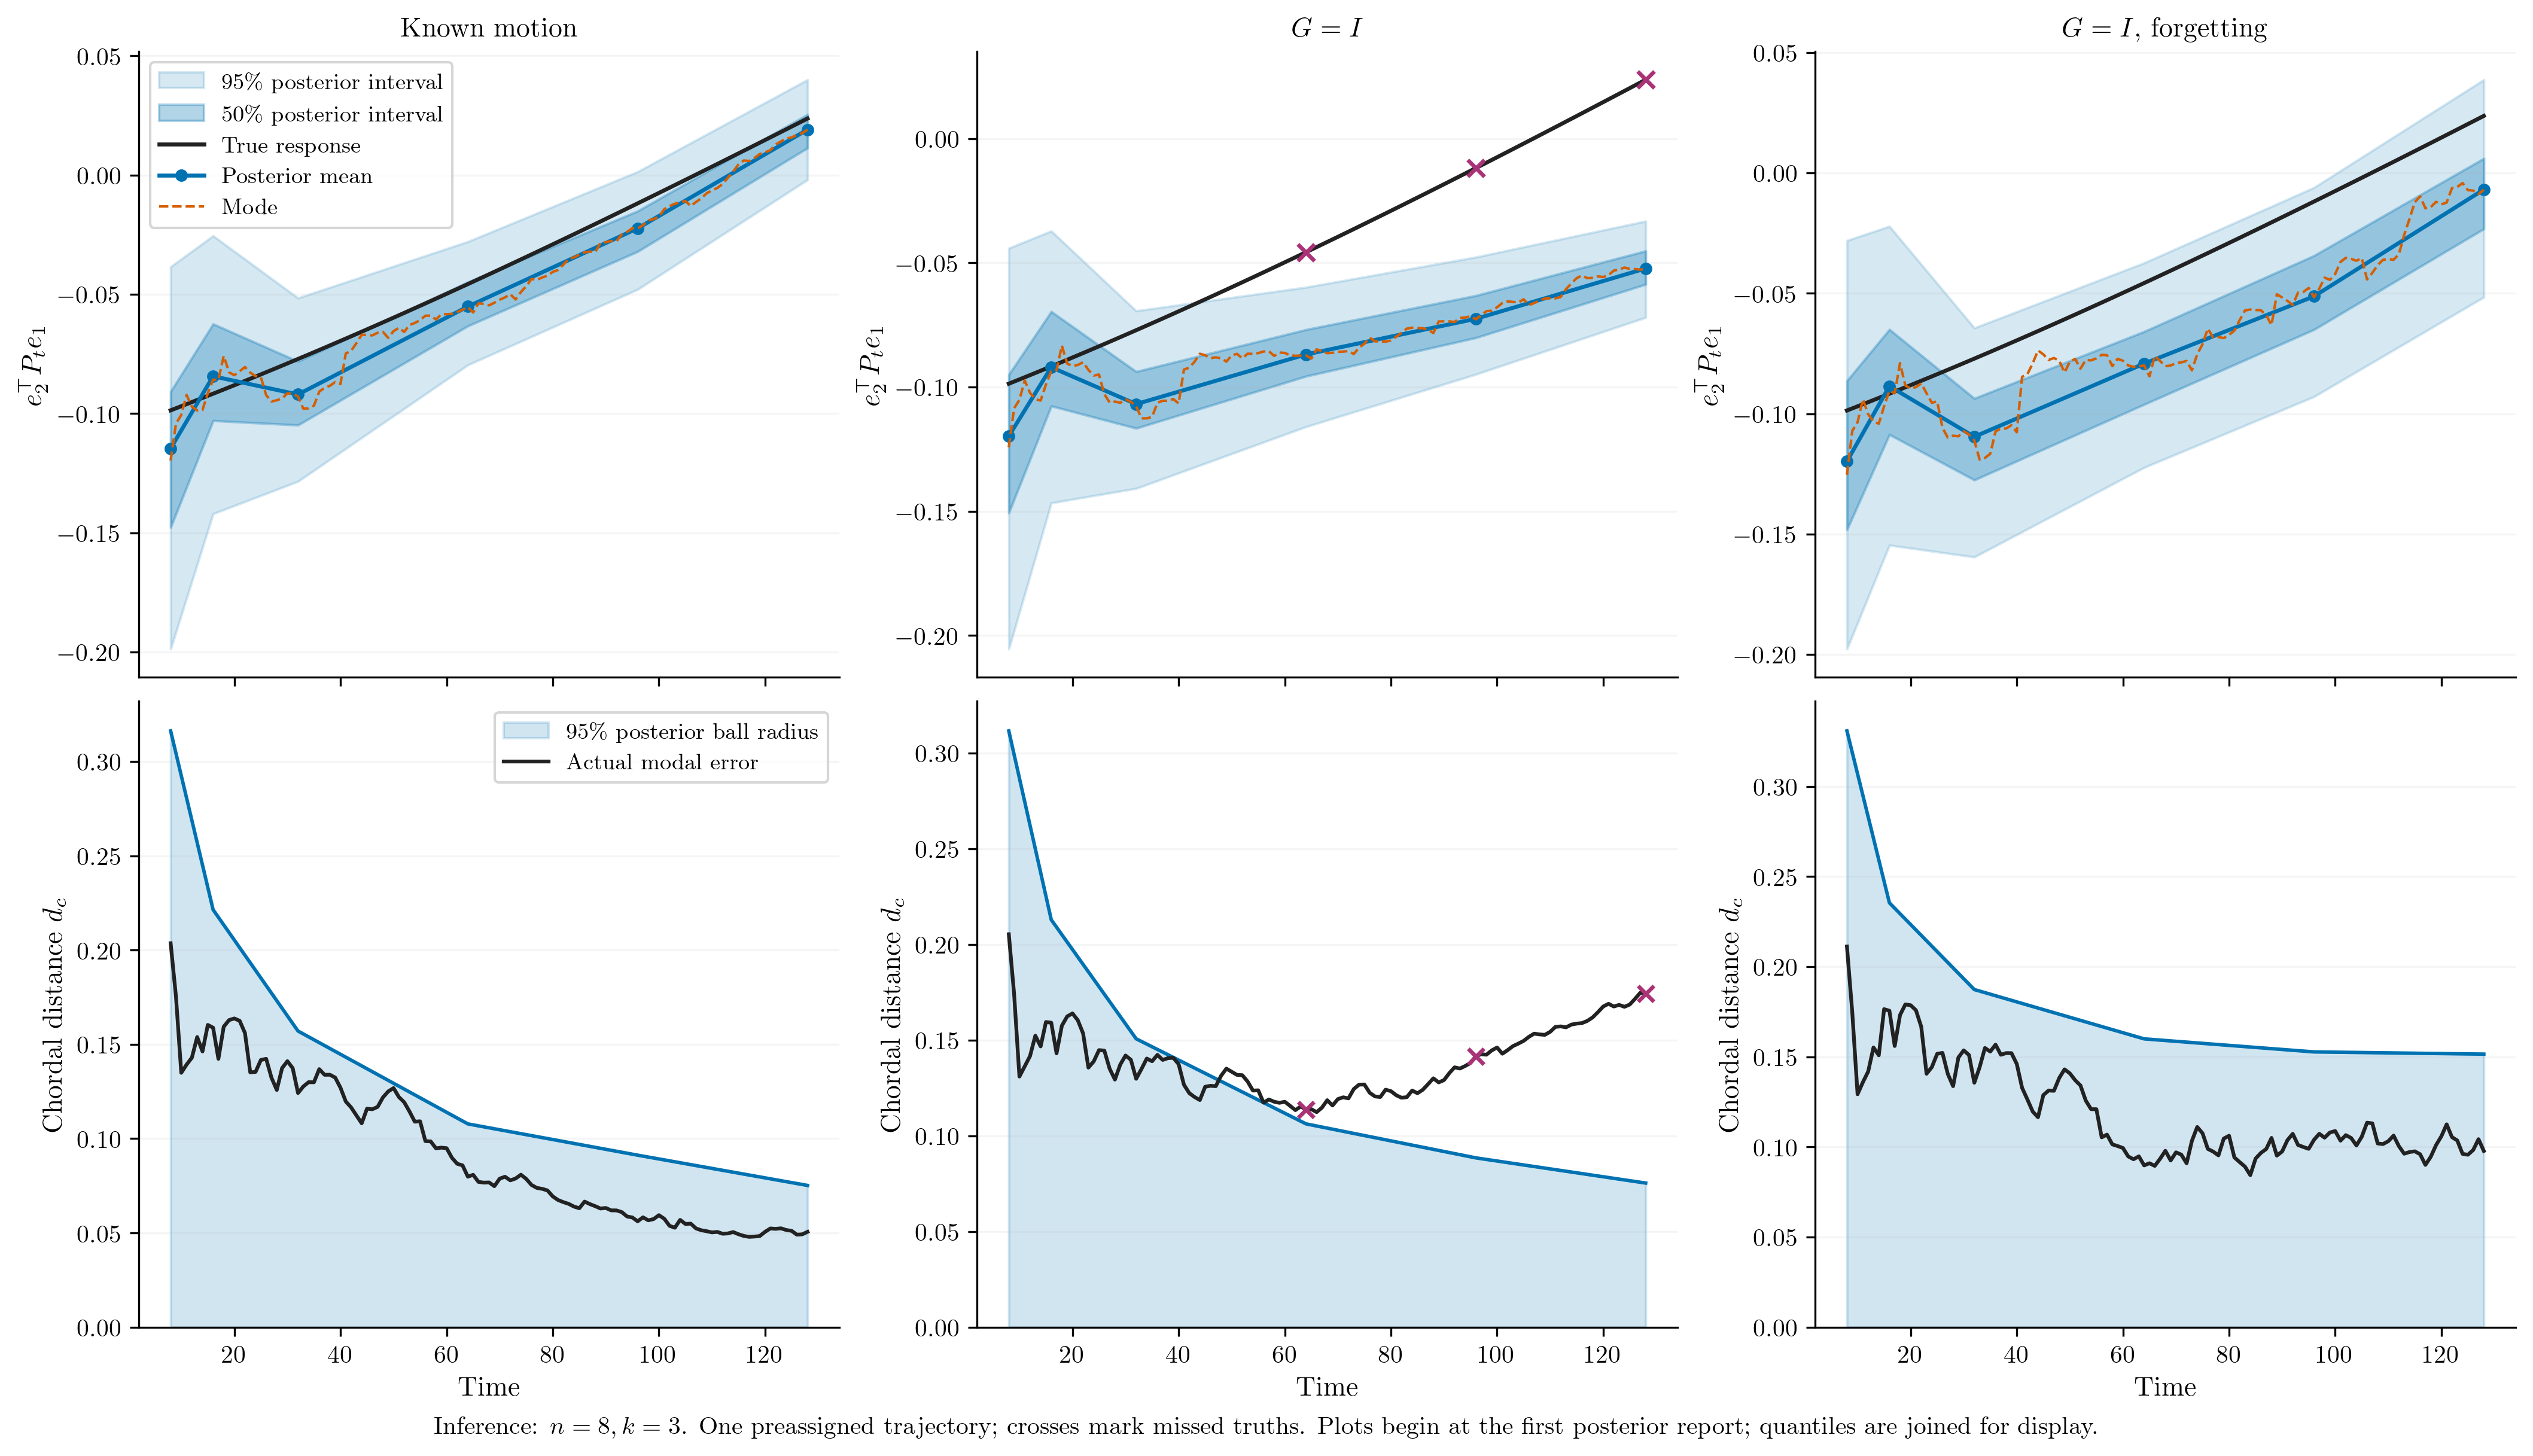

In [3]:
# Saved arrays/tables only; edit the plotting code below freely.
story = load_field_data(ROOT, 'drift')
fast = False

DPI = 300
FIGSIZE = (14, 8)
SAVE_PDF = True

keys = ['known_fast', 'identity_fast', 'forget_fast'] if fast else ['known_slow', 'identity_slow', 'forget_slow']
posterior = story['posterior']
modal = story['modal']
bounds = story['bounds']
fig, axs = plt.subplots(2, 3, figsize=FIGSIZE, dpi=DPI, layout='constrained', sharex=True)
for col, key in enumerate(keys):
    g = posterior[(posterior.trial == 0) & (posterior.protocol == key)].sort_values('t')
    truth = modal[(modal.trial == 0) & (modal.protocol == key) & (modal.t >= g.t.min())].sort_values('t')
    ax = axs[0, col]
    ax.fill_between(g.t, g.q025, g.q975, color='#0072B2', alpha=0.16, label='95\\% posterior interval')
    ax.fill_between(g.t, g.q25, g.q75, color='#0072B2', alpha=0.3, label='50\\% posterior interval')
    ax.plot(truth.t, truth.true_response, color='#222222', lw=1.6, label='True response')
    ax.plot(g.t, g.mean_response, 'o-', color='#0072B2', ms=4, label='Posterior mean')
    ax.plot(truth.t, truth.mode_response, ls='--', color='#D55E00', lw=1, label='Mode')
    bad = ~g.clean_response_covered.astype(bool)
    ax.scatter(g.loc[bad, 't'], g.loc[bad, 'true_response'], marker='x', s=45, color='#AA3377', zorder=5)
    ax.set_title(PROTOCOLS[key])
    ax.set_ylabel('$e_2^\\top P_t e_1$')
    ax = axs[1, col]
    b = bounds[(bounds.trial == 0) & (bounds.protocol == key)].sort_values('t')
    ax.fill_between(g.t, 0, g.posterior_radius, color='#0072B2', alpha=0.18, label='95\\% posterior ball radius')
    ax.plot(g.t, g.posterior_radius, color='#0072B2', lw=1.4)
    ax.plot(truth.t, truth.chordal_error, color='#222222', lw=1.5, label='Actual modal error')
    misses = ~g.ball_covered.astype(bool)
    err = b.set_index('t').chordal_error.reindex(g.loc[misses, 't'])
    ax.scatter(g.loc[misses, 't'], err, marker='x', s=40, color='#AA3377', zorder=4)
    ax.set(xlabel='Time', ylabel='Chordal distance $d_c$')
    ax.set_ylim(bottom=0)
    for sub in axs[:, col]:
        sub.grid(axis='y', alpha=0.12)
    if not g.sampling_ok.astype(bool).all():
        axs[0, col].text(0.02, 0.02, 'Some capped sampler diagnostics failed', transform=axs[0, col].transAxes, color='#AA3377', fontsize=9)
axs[0, 0].legend(fontsize=9, loc='best')
axs[1, 0].legend(fontsize=9, loc='best')
fig.supxlabel('Inference: $n=8,k=3$. One preassigned trajectory; crosses mark missed truths. Plots begin at the first posterior report; quantiles are joined for display.', fontsize=10)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_prediction_fans.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

## See the prediction distribution, not just its centre
Dots are projected Monte Carlo predictions; diamonds and circles give mean and modal predictions, and stars show the truth. The axes are two fixed coordinates of an eight-dimensional response. All eight dimensions and rank three are used in inference.

A cloud can become small without containing the truth when old evidence accumulates under an incorrect transition model. The exact-motion and forgetting controls show which part of this behavior is due to the maintained state model. This projection is a visualization, not a two-dimensional credible region for the full subspace.

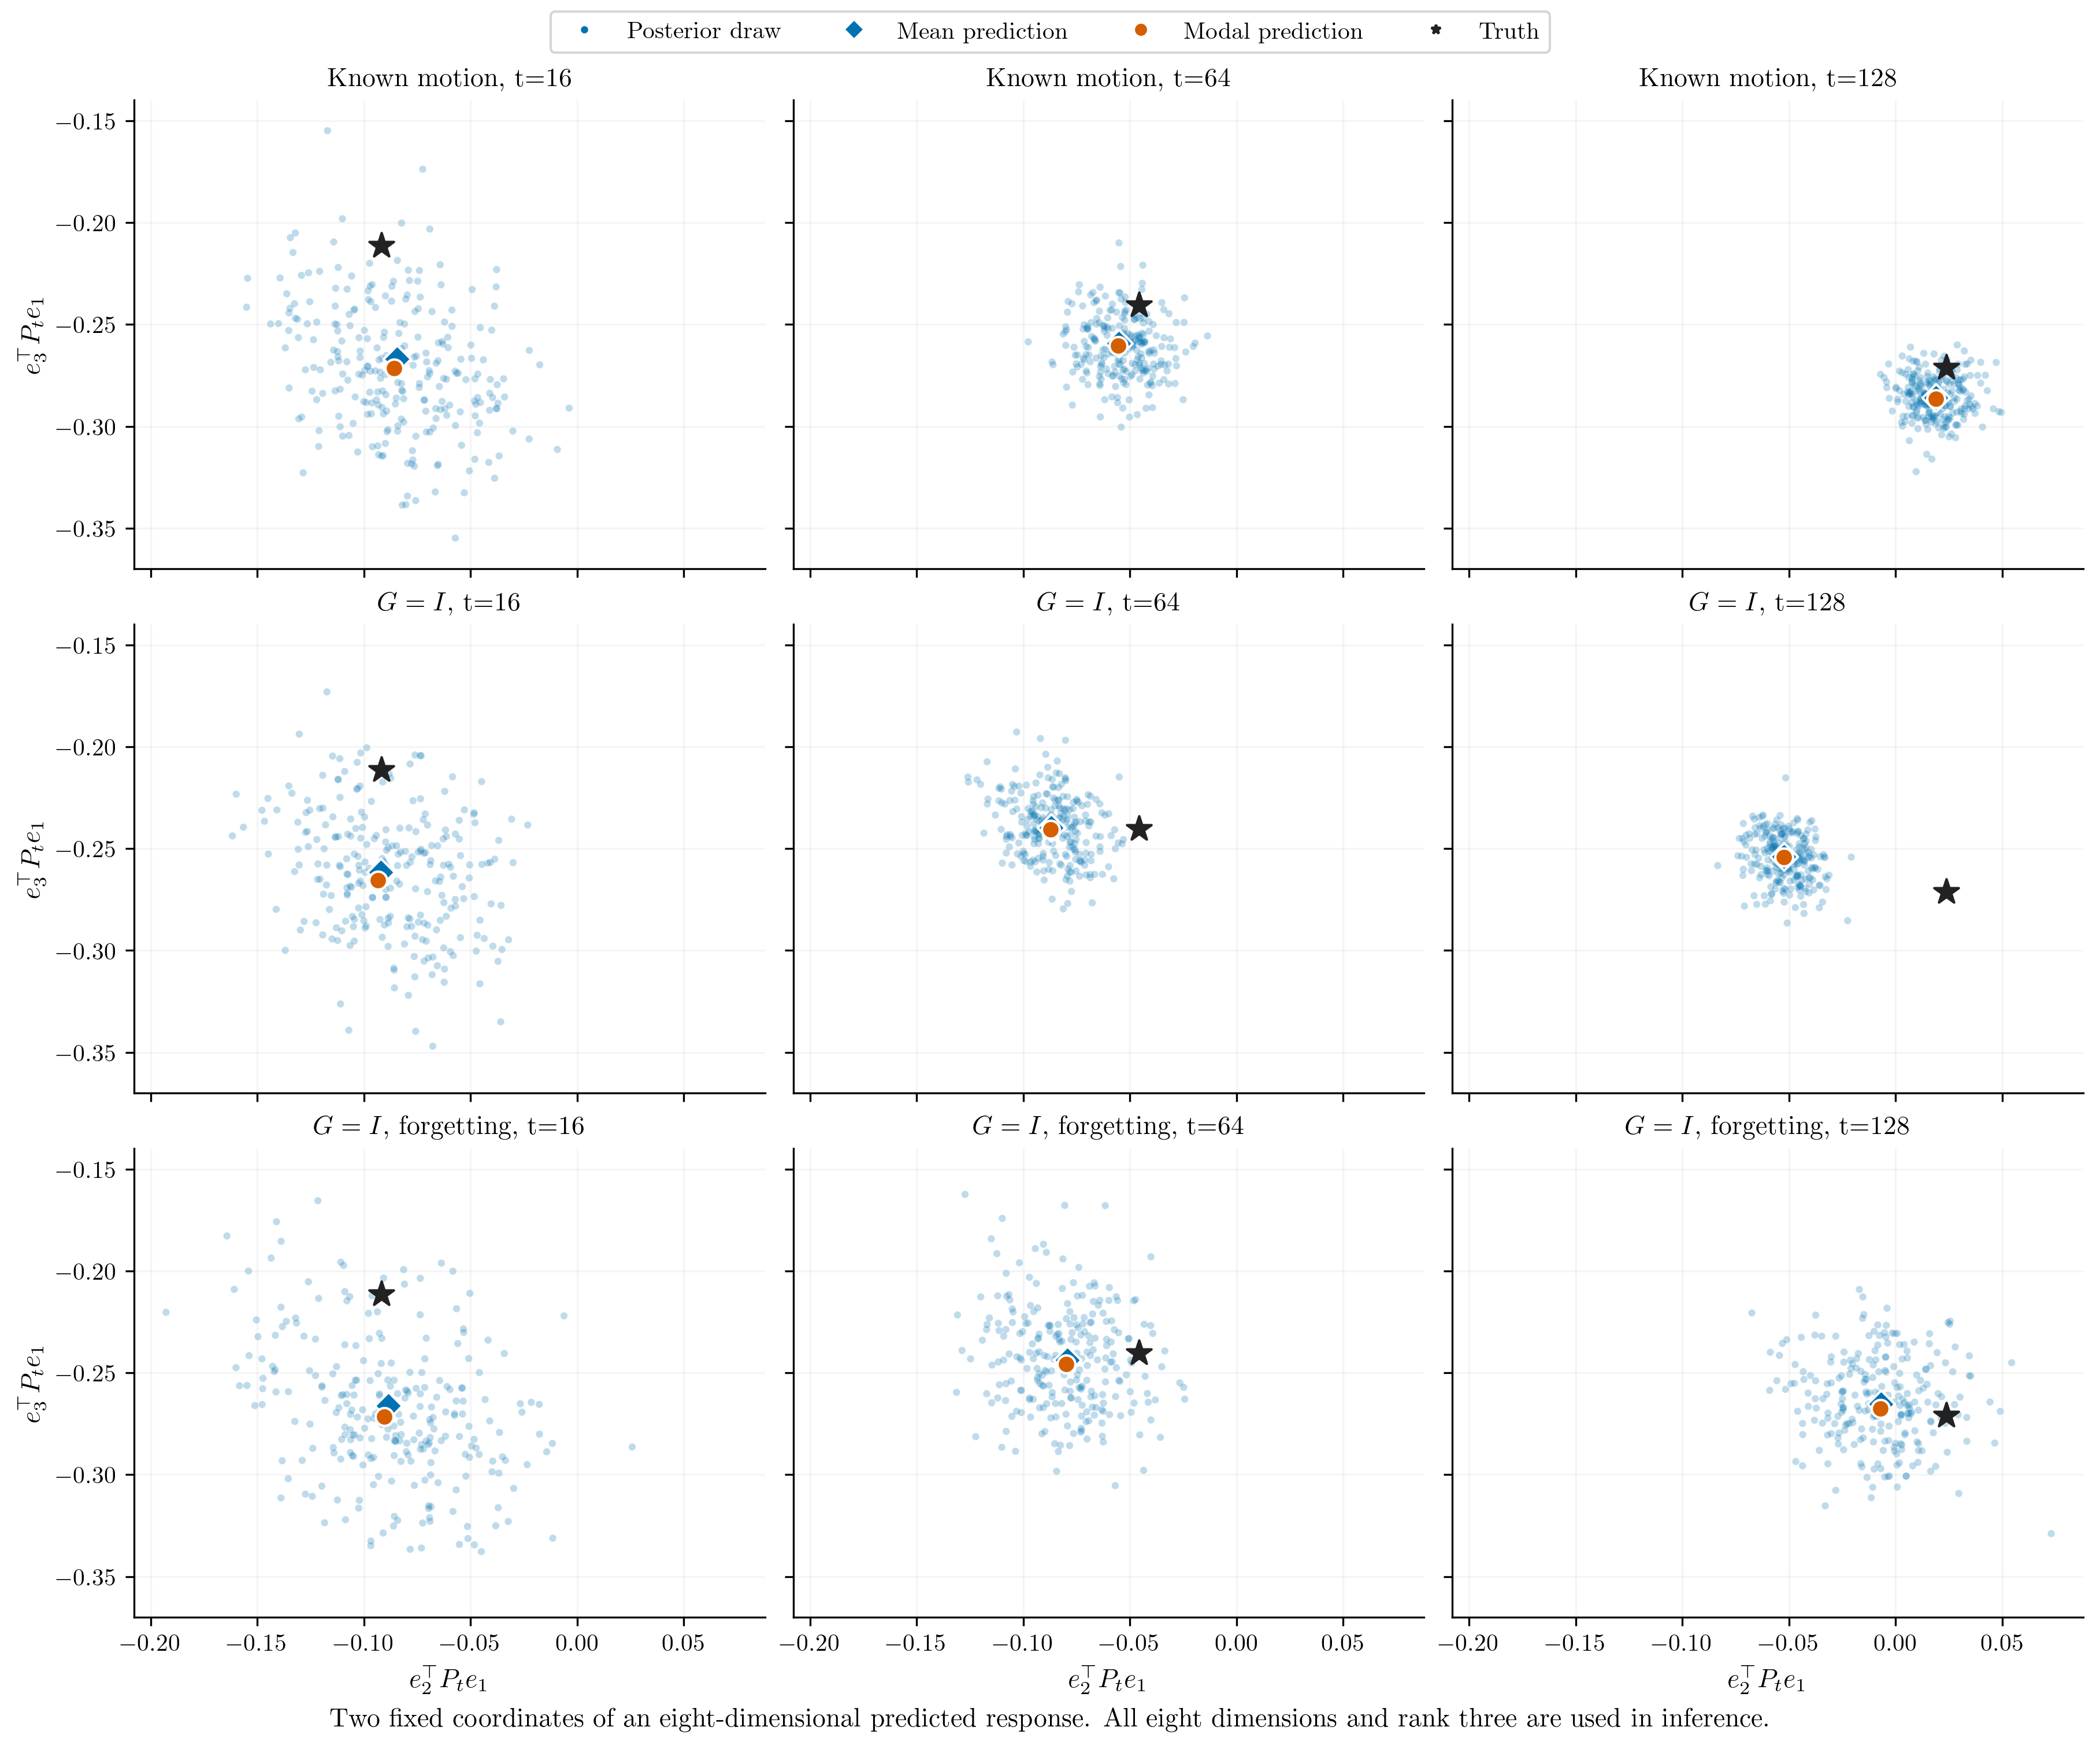

In [4]:
# Saved arrays/tables only; edit the plotting code below freely.
story = load_field_data(ROOT, 'drift')
fast = False

DPI = 300
FIGSIZE = (12, 10)
SAVE_PDF = True

keys = ['known_fast', 'identity_fast', 'forget_fast'] if fast else ['known_slow', 'identity_slow', 'forget_slow']
data = story['cloud']
times = [16, 64, 128]
selected = data[data.protocol.isin(keys)]
xmin = min(selected.x.min(), selected.true_x.min()) - 0.015
xmax = max(selected.x.max(), selected.true_x.max()) + 0.015
ymin = min(selected.y.min(), selected.true_y.min()) - 0.015
ymax = max(selected.y.max(), selected.true_y.max()) + 0.015
fig, axs = plt.subplots(3, 3, figsize=FIGSIZE, dpi=DPI, layout='constrained', sharex=True, sharey=True)
for row, key in enumerate(keys):
    for col, time in enumerate(times):
        g = data[(data.protocol == key) & (data.t == time)]
        ax = axs[row, col]
        r = g.iloc[0]
        ax.scatter(g.x, g.y, s=9, color='#0072B2', alpha=0.25, edgecolors='none')
        ax.scatter(r.mean_x, r.mean_y, s=65, marker='D', color='#0072B2', edgecolor='white', zorder=4)
        ax.scatter(r.mode_x, r.mode_y, s=55, marker='o', color='#D55E00', edgecolor='white', zorder=4)
        ax.scatter(r.true_x, r.true_y, s=115, marker='*', color='#222222', zorder=5)
        ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), title=f'{PROTOCOLS[key]}, t={time}')
        if row == 2:
            ax.set_xlabel('$e_2^\\top P_t e_1$')
        if col == 0:
            ax.set_ylabel('$e_3^\\top P_t e_1$')
        ax.grid(alpha=0.12)
fig.legend(handles=[Line2D([], [], marker='.', ls='', color='#0072B2', label='Posterior draw'), Line2D([], [], marker='D', ls='', color='#0072B2', label='Mean prediction'), Line2D([], [], marker='o', ls='', color='#D55E00', label='Modal prediction'), Line2D([], [], marker='*', ls='', color='#222222', label='Truth')], loc='outside upper center', ncol=4, fontsize=10)
fig.supxlabel('Two fixed coordinates of an eight-dimensional predicted response. All eight dimensions and rank three are used in inference.', fontsize=11)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_prediction_clouds.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

## When the tracking theorem is informative
The left panel is the theorem's noise-versus-drift budget at the fixed terminal time. The initial parameter is zero. The certificate condition holds below the diagonal boundary, where the combined perturbation is less than half the excitation gap. Forgetting reduces stale-motion bias but also reduces retained information; arrows join protocol median ratios to display this tradeoff.

The right panel compares actual error with the theorem bound **only where its condition holds**. The bound can be informative with G=I and slow unmodelled motion. Fast-motion cases outside the condition receive no certificate; they are not counted as successful bounds. This is a conditional known-input, fixed-true-noise theorem, unlike the passive credible-region experiment in the supplement.

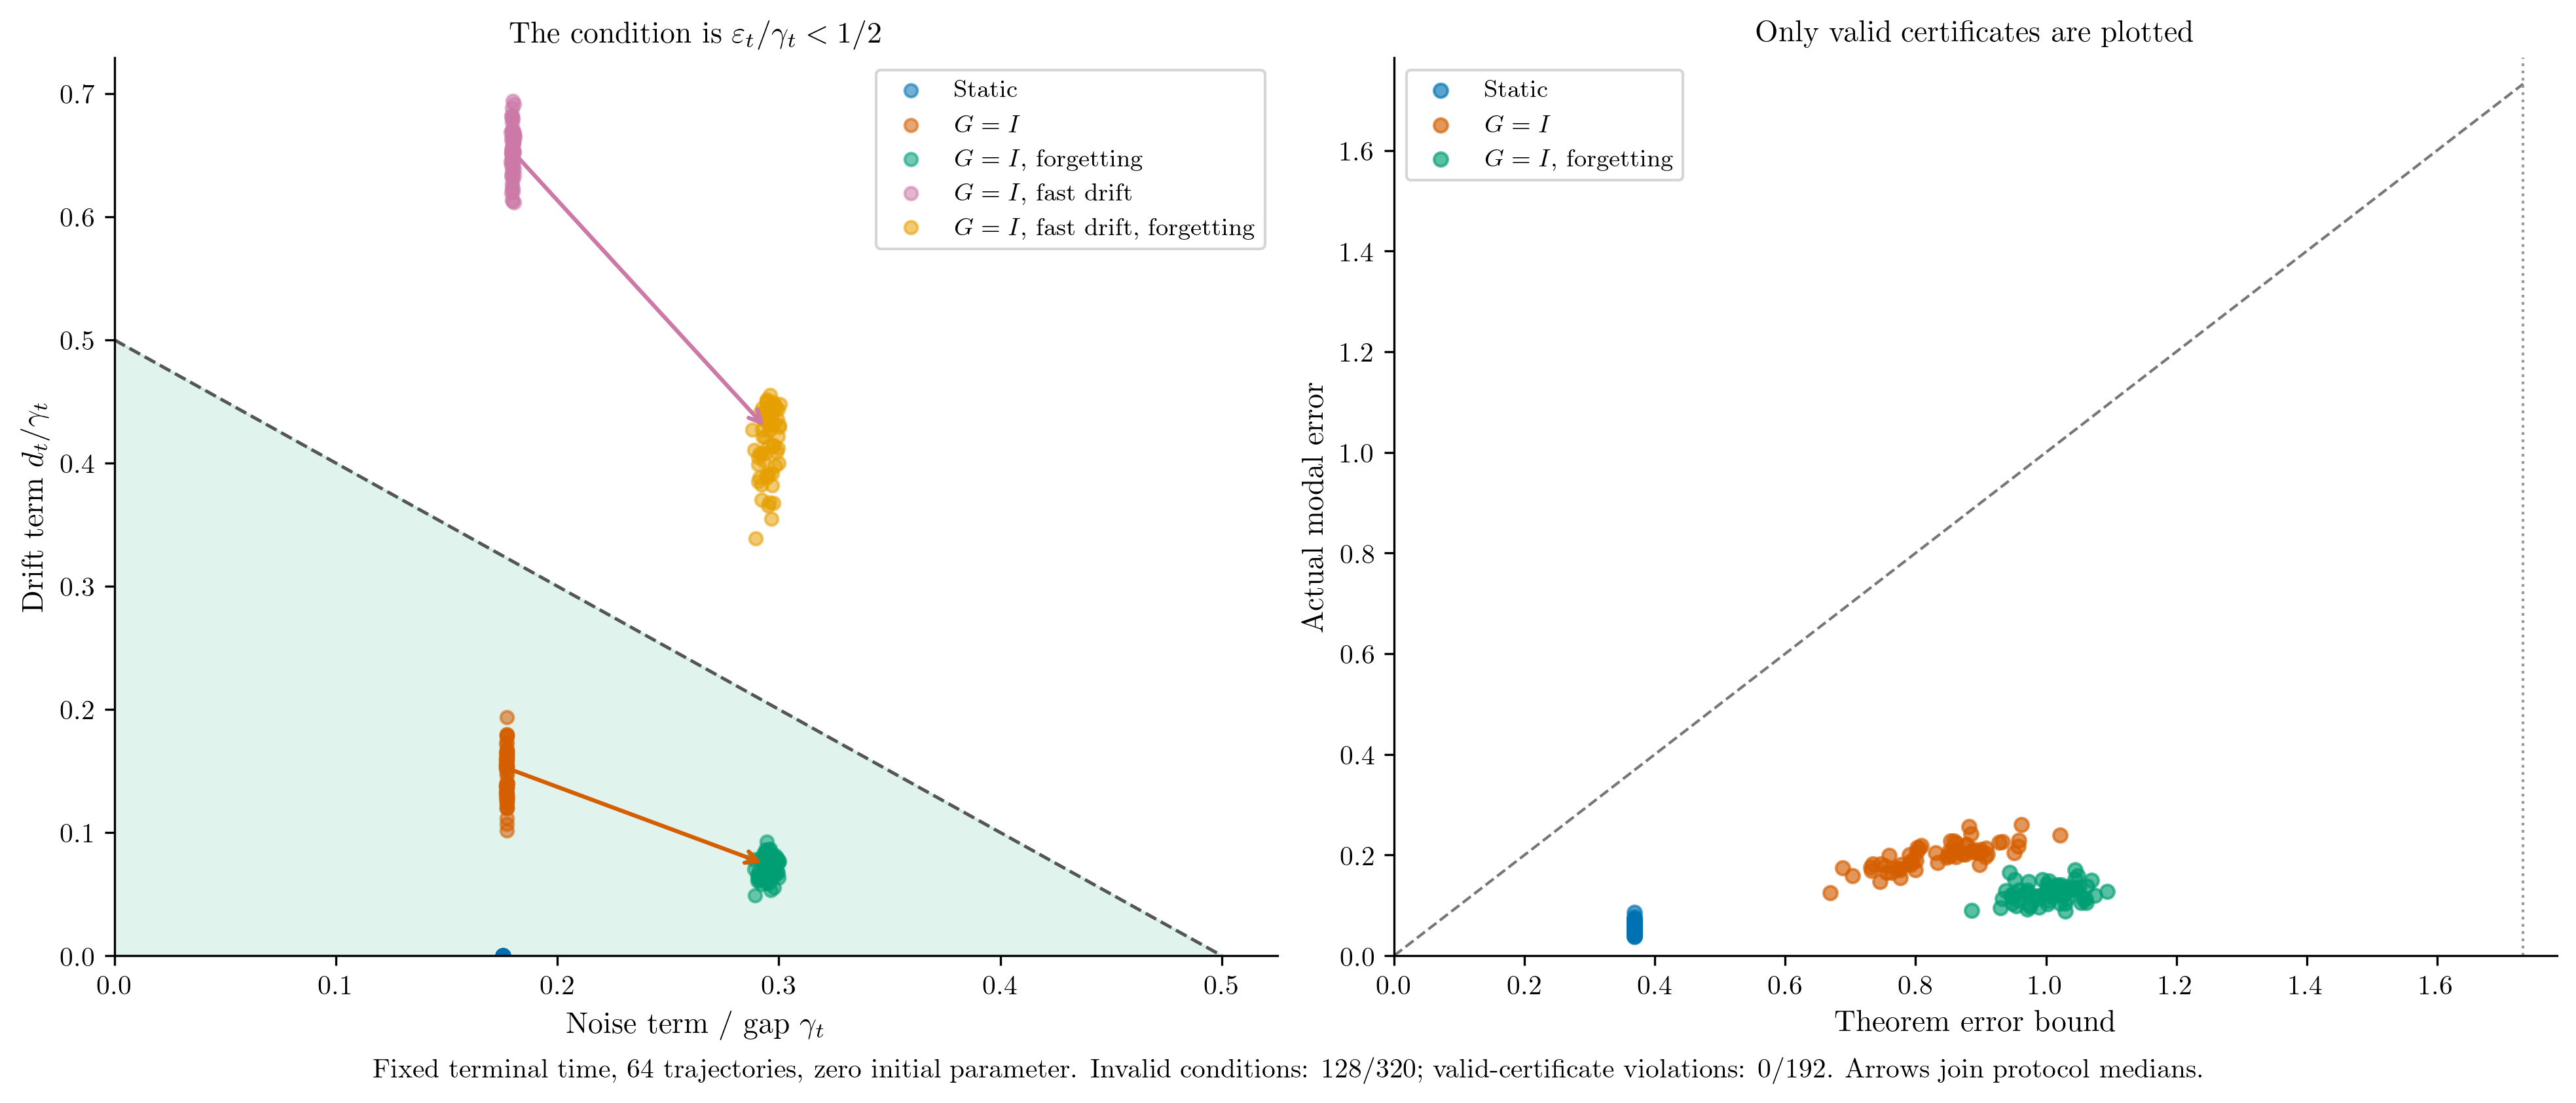

In [5]:
# Saved arrays/tables only; edit the plotting code below freely.
story = load_field_data(ROOT, 'drift')

DPI = 300
FIGSIZE = (13, 5.5)
SAVE_PDF = True

b = story['bounds']
g = b[b.t == b.t.max()]
keys = ['static', 'identity_slow', 'forget_slow', 'identity_fast', 'forget_fast']
g = g[g.protocol.isin(keys)]
fig, axs = plt.subplots(1, 2, figsize=FIGSIZE, dpi=DPI, layout='constrained')
ax = axs[0]
ax.fill([0, 0.5, 0], [0, 0, 0.5], color='#009E73', alpha=0.12)
ax.plot([0, 0.5], [0.5, 0], ls='--', color='#555555', lw=1.2)
for key in keys:
    h = g[g.protocol == key]
    ax.scatter(h.noise_term / h.gamma, h.drift_term / h.gamma, s=22, alpha=0.55, color=PALETTE[key], label=PROTOCOLS[key])
for a, c in [('identity_slow', 'forget_slow'), ('identity_fast', 'forget_fast')]:
    u = g[g.protocol == a]
    v = g[g.protocol == c]
    start = (np.median(u.noise_term / u.gamma), np.median(u.drift_term / u.gamma))
    end = (np.median(v.noise_term / v.gamma), np.median(v.drift_term / v.gamma))
    ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', color=PALETTE[a], lw=1.5))
ax.set(xlabel='Noise term / gap $\\gamma_t$', ylabel='Drift term $d_t/\\gamma_t$', title='The condition is $\\varepsilon_t/\\gamma_t<1/2$')
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend(fontsize=9)
ax = axs[1]
valid = g[g.valid.astype(bool)]
for key in keys:
    h = valid[valid.protocol == key]
    if len(h):
        ax.scatter(h.bound, h.chordal_error, s=25, alpha=0.65, color=PALETTE[key], label=PROTOCOLS[key])
ceiling = float(g.ceiling.iloc[0])
ax.plot([0, ceiling], [0, ceiling], '--', color='#777777', lw=1)
ax.axvline(ceiling, ls=':', color='#999999', lw=1)
ax.set(xlabel='Theorem error bound', ylabel='Actual modal error', title='Only valid certificates are plotted', xlim=(0, ceiling * 1.03), ylim=(0, ceiling * 1.03))
ax.legend(fontsize=9)
invalid = int((~g.valid.astype(bool)).sum())
violations = int(valid.bound_violated.astype(bool).sum())
fig.supxlabel(f"Fixed terminal time, {story['config']['modal_trials']} trajectories, zero initial parameter. Invalid conditions: {invalid}/{len(g)}; valid-certificate violations: {violations}/{len(valid)}. Arrows join protocol medians.", fontsize=10)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_drift_certificate.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

## Monte Carlo error and coverage are separate questions
The left panel shows repeated-data tracking errors across 64 independent trajectories. On the right, each point compares actual modal error with the posterior-ball radius for one of 16 posterior-evaluated trajectories. Above the diagonal, that credible ball misses the true state.

These panels can show an informative modal bound and undercoverage simultaneously. Good point tracking does not prove calibrated state uncertainty. The 16-trial coverage estimates have wide binomial uncertainty; a favorable forgetting result is not a general coverage theorem. Static and exact-motion controls are orthogonally coupled, not counted as additional independent Monte Carlo replicates.

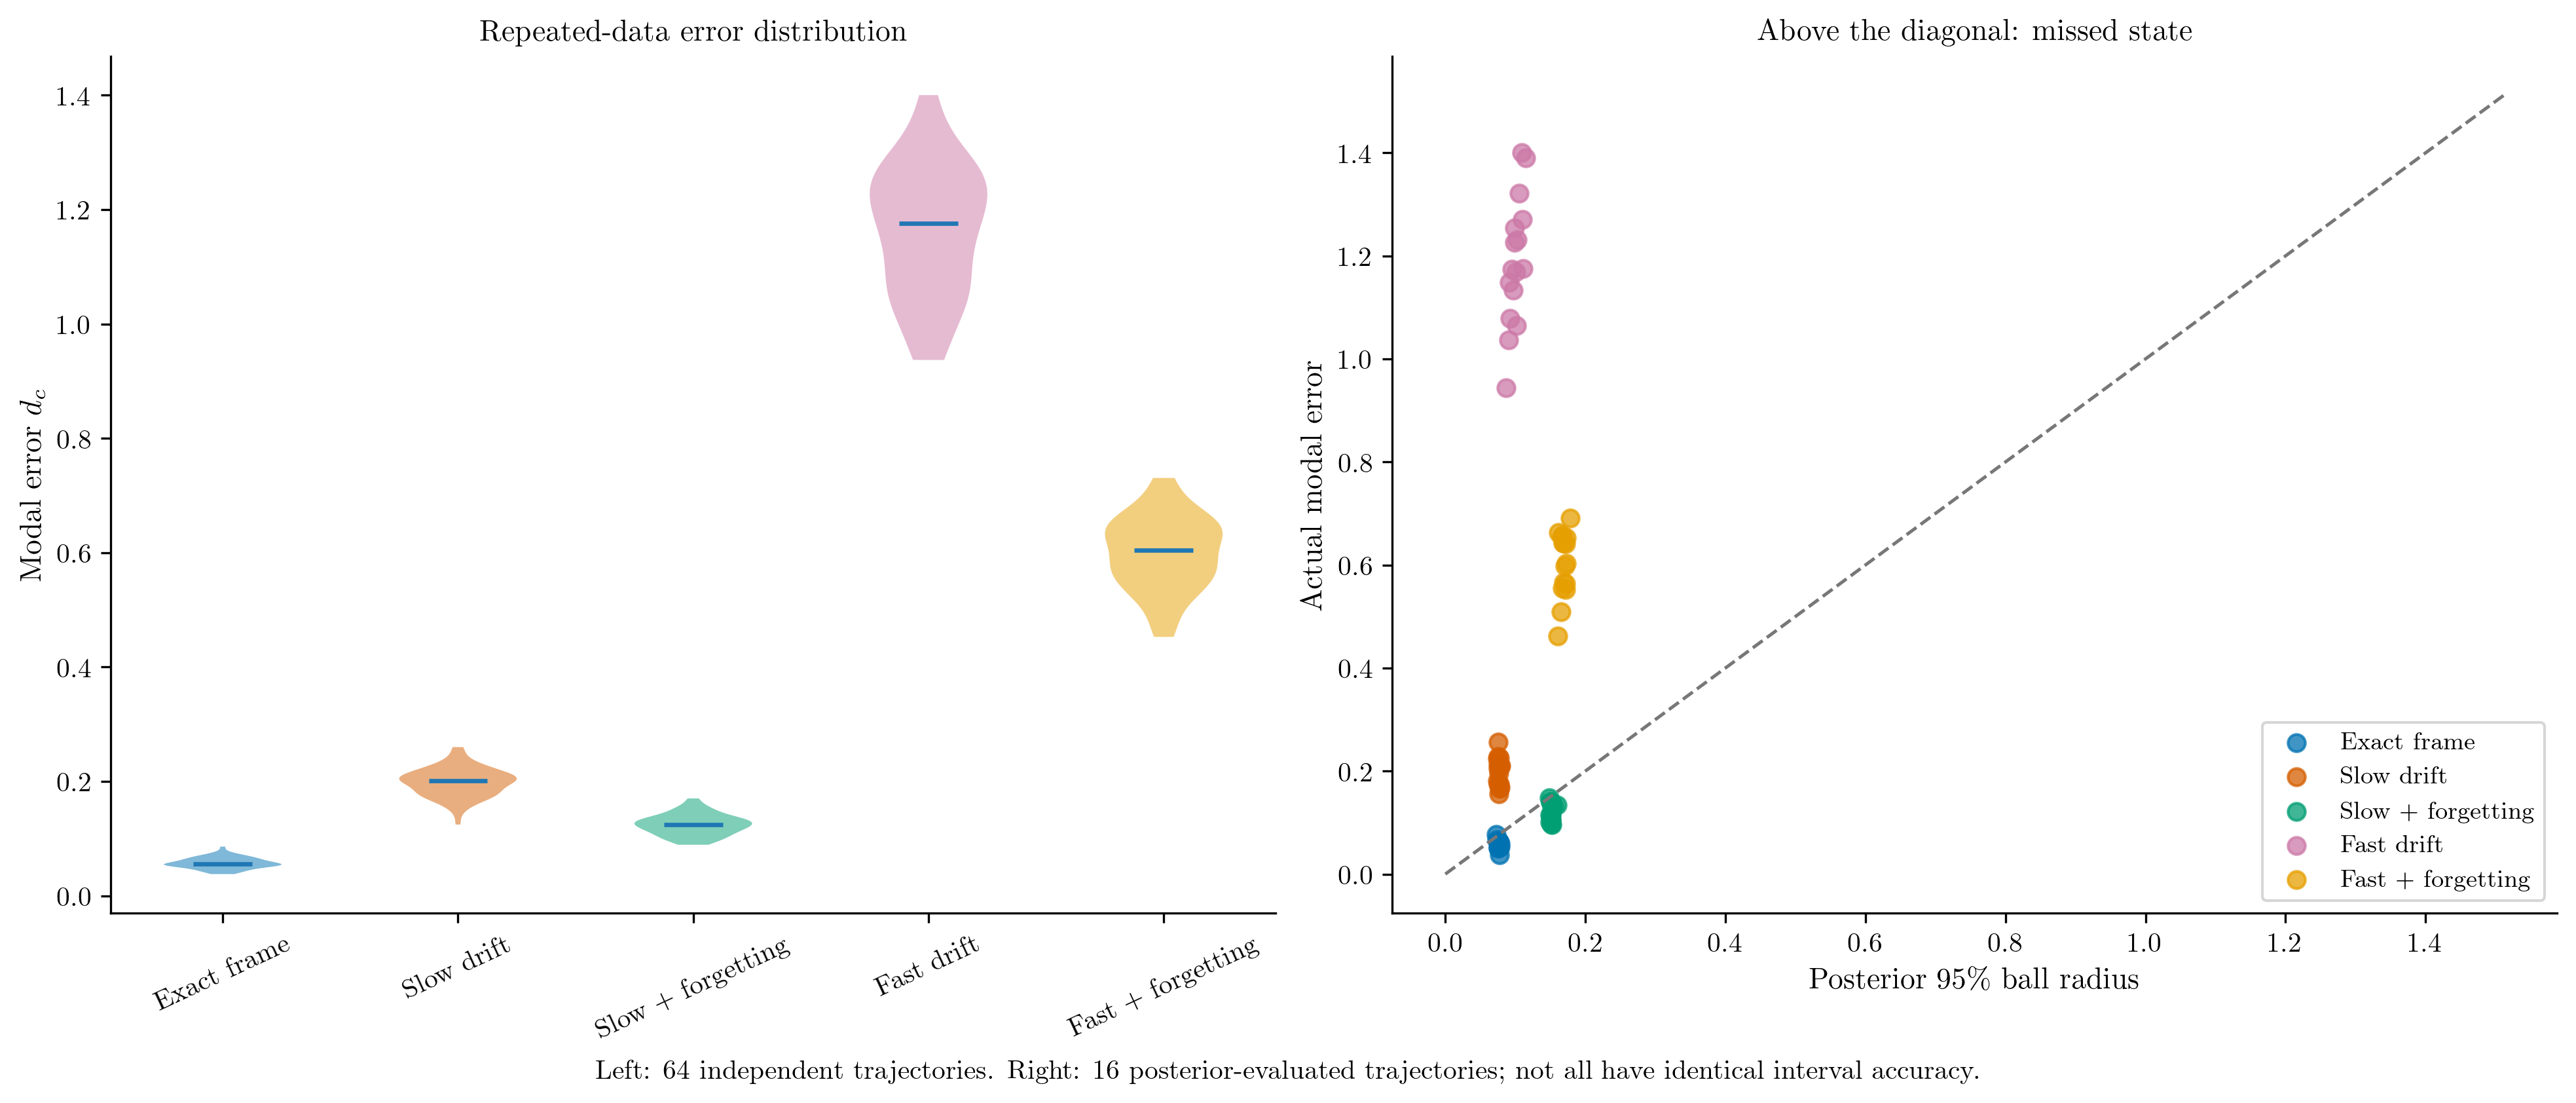

In [6]:
# Saved arrays/tables only; edit the plotting code below freely.
story = load_field_data(ROOT, 'drift')

DPI = 300
FIGSIZE = (13, 5.5)
SAVE_PDF = True

b = story['bounds']
g = b[b.t == b.t.max()]
p = story['posterior']
p = p[p.t == p.t.max()]
keys = ['static', 'identity_slow', 'forget_slow', 'identity_fast', 'forget_fast']
labels = ['Exact frame', 'Slow drift', 'Slow + forgetting', 'Fast drift', 'Fast + forgetting']
fig, axs = plt.subplots(1, 2, figsize=FIGSIZE, dpi=DPI, layout='constrained')
values = [g[g.protocol == key].chordal_error.to_numpy() for key in keys]
violin = axs[0].violinplot(values, positions=range(5), showmeans=False, showmedians=True, showextrema=False)
for body, key in zip(violin['bodies'], keys):
    body.set_facecolor(PALETTE[key])
    body.set_alpha(0.5)
axs[0].set(xticks=range(5), xticklabels=labels, ylabel='Modal error $d_c$', title='Repeated-data error distribution')
axs[0].tick_params(axis='x', rotation=25)
upper = 0
for key, label in zip(keys, labels):
    h = p[p.protocol == key]
    r = g[g.protocol == key].set_index('trial').chordal_error.reindex(h.trial).to_numpy()
    axs[1].scatter(h.posterior_radius, r, s=40, alpha=0.75, color=PALETTE[key], label=label)
    upper = max(upper, h.posterior_radius.max(), max(r))
axs[1].plot([0, upper * 1.08], [0, upper * 1.08], '--', color='#777777', lw=1.2)
axs[1].set(xlabel='Posterior 95\\% ball radius', ylabel='Actual modal error', title='Above the diagonal: missed state')
axs[1].legend(fontsize=9)
fig.supxlabel(f"Left: {story['config']['modal_trials']} independent trajectories. Right: {story['config']['posterior_trials']} posterior-evaluated trajectories; not all have identical interval accuracy.", fontsize=10)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_monte_carlo.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

## Supplementary comparisons and numerical checks
The remaining sections retain passive reconstruction, dense parameter comparisons, the low-dimensional controlled decision study, and approximation diagnostics.

### Fast drift stress test
The same preassigned design with faster residual motion exposes the limits of identity prediction and forgetting.

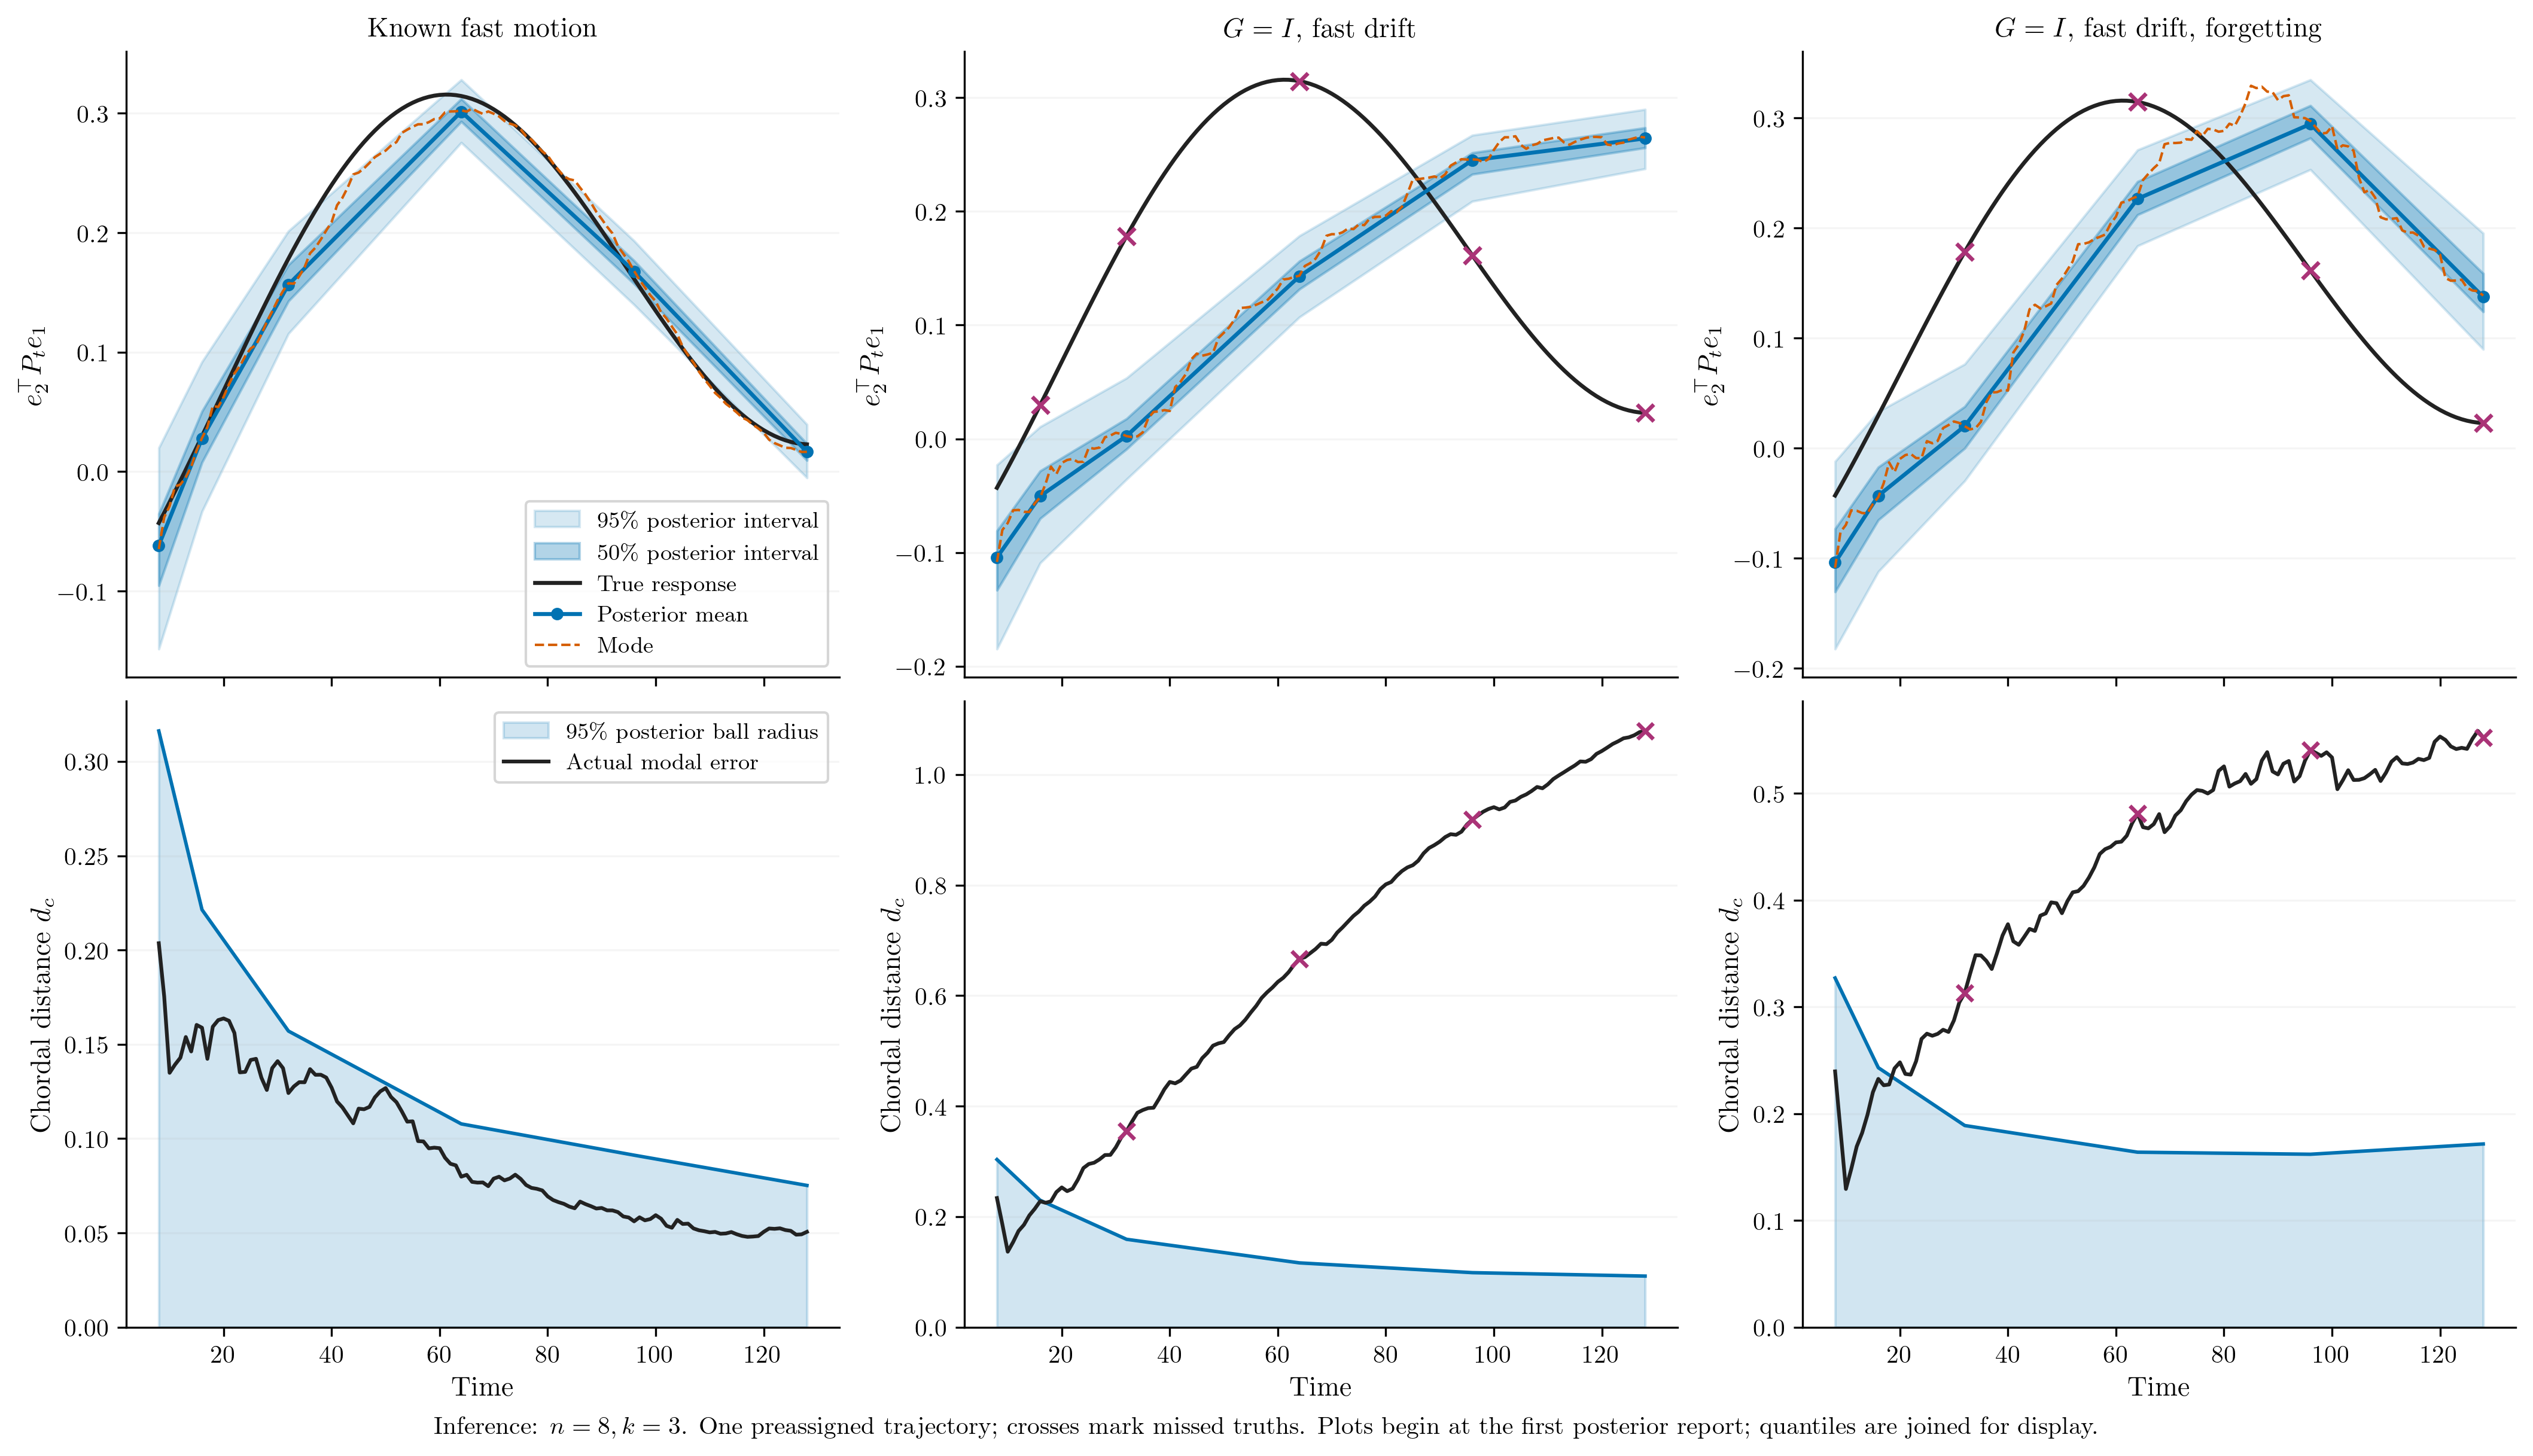

In [7]:
# Saved arrays/tables only; edit the plotting code below freely.
story = load_field_data(ROOT, 'drift')
fast = True

DPI = 300
FIGSIZE = (14, 8)
SAVE_PDF = True

keys = ['known_fast', 'identity_fast', 'forget_fast'] if fast else ['known_slow', 'identity_slow', 'forget_slow']
posterior = story['posterior']
modal = story['modal']
bounds = story['bounds']
fig, axs = plt.subplots(2, 3, figsize=FIGSIZE, dpi=DPI, layout='constrained', sharex=True)
for col, key in enumerate(keys):
    g = posterior[(posterior.trial == 0) & (posterior.protocol == key)].sort_values('t')
    truth = modal[(modal.trial == 0) & (modal.protocol == key) & (modal.t >= g.t.min())].sort_values('t')
    ax = axs[0, col]
    ax.fill_between(g.t, g.q025, g.q975, color='#0072B2', alpha=0.16, label='95\\% posterior interval')
    ax.fill_between(g.t, g.q25, g.q75, color='#0072B2', alpha=0.3, label='50\\% posterior interval')
    ax.plot(truth.t, truth.true_response, color='#222222', lw=1.6, label='True response')
    ax.plot(g.t, g.mean_response, 'o-', color='#0072B2', ms=4, label='Posterior mean')
    ax.plot(truth.t, truth.mode_response, ls='--', color='#D55E00', lw=1, label='Mode')
    bad = ~g.clean_response_covered.astype(bool)
    ax.scatter(g.loc[bad, 't'], g.loc[bad, 'true_response'], marker='x', s=45, color='#AA3377', zorder=5)
    ax.set_title(PROTOCOLS[key])
    ax.set_ylabel('$e_2^\\top P_t e_1$')
    ax = axs[1, col]
    b = bounds[(bounds.trial == 0) & (bounds.protocol == key)].sort_values('t')
    ax.fill_between(g.t, 0, g.posterior_radius, color='#0072B2', alpha=0.18, label='95\\% posterior ball radius')
    ax.plot(g.t, g.posterior_radius, color='#0072B2', lw=1.4)
    ax.plot(truth.t, truth.chordal_error, color='#222222', lw=1.5, label='Actual modal error')
    misses = ~g.ball_covered.astype(bool)
    err = b.set_index('t').chordal_error.reindex(g.loc[misses, 't'])
    ax.scatter(g.loc[misses, 't'], err, marker='x', s=40, color='#AA3377', zorder=4)
    ax.set(xlabel='Time', ylabel='Chordal distance $d_c$')
    ax.set_ylim(bottom=0)
    for sub in axs[:, col]:
        sub.grid(axis='y', alpha=0.12)
    if not g.sampling_ok.astype(bool).all():
        axs[0, col].text(0.02, 0.02, 'Some capped sampler diagnostics failed', transform=axs[0, col].transAxes, color='#AA3377', fontsize=9)
axs[0, 0].legend(fontsize=9, loc='best')
axs[1, 0].legend(fontsize=9, loc='best')
fig.supxlabel('Inference: $n=8,k=3$. One preassigned trajectory; crosses mark missed truths. Plots begin at the first posterior report; quantiles are joined for display.', fontsize=10)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_fast_drift.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

### Attribute the gains correctly
The three maps compare the posterior mean against GROUSE, its **own mode**, and rolling PCA. Blue means lower field MSE; red means higher MSE. Cells show paired absolute-loss differences scaled by the observed mean reference loss, with paired 95% intervals on that scale—not a confidence interval for a random loss ratio.

Large gains versus GROUSE under mismatch should not be attributed entirely to Bayesian averaging: the mode/EW-PCA control already captures most of them. The rolling-PCA panel prevents selecting only a weak reference. Intervals crossing zero do not establish a difference.

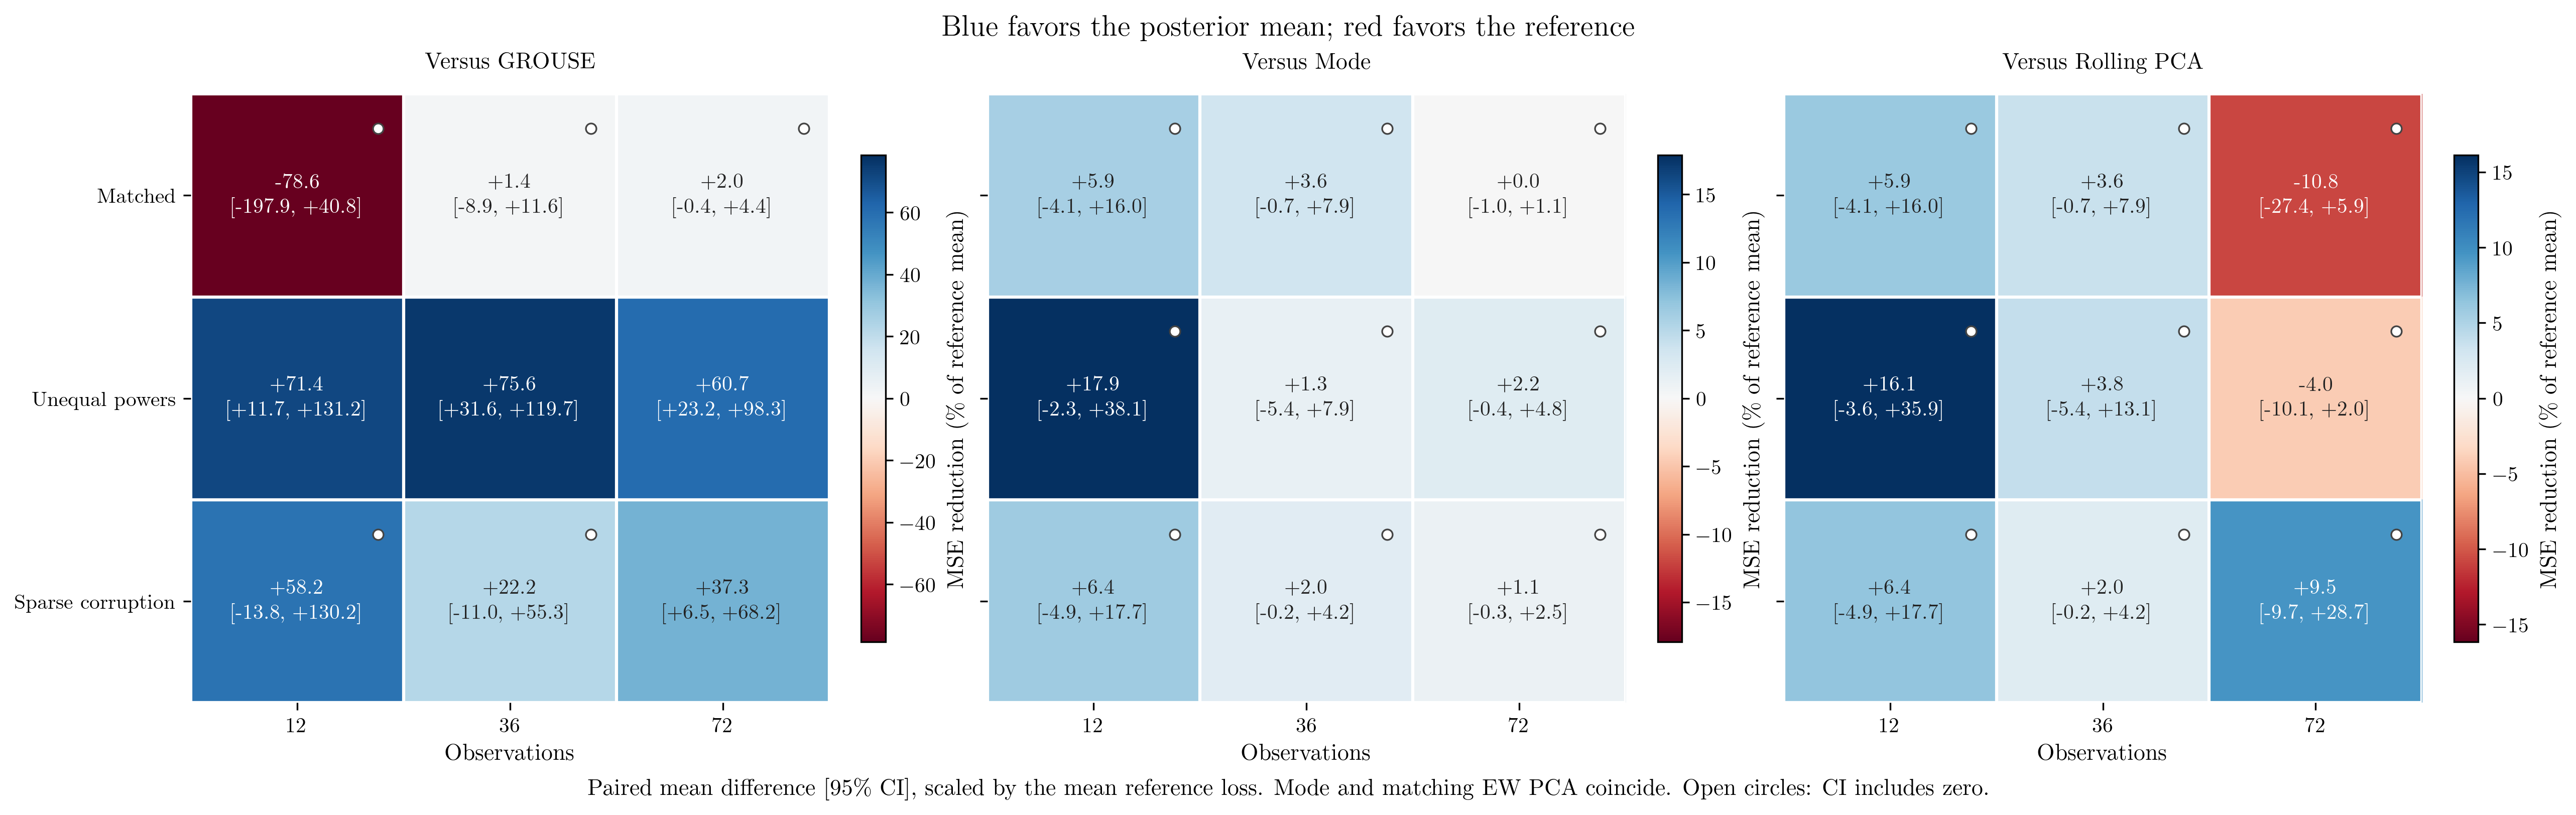

In [8]:
# Saved arrays/tables only; edit the plotting code below freely.
result = load_field_data(ROOT, 'application')

DPI = 300
FIGSIZE = (17, 5.3)
SAVE_PDF = True

frame = result['metrics']
scenarios = [s for s in FIELD_SCENARIOS if s in frame.scenario.unique()]
references = ['GROUSE', 'Mode', 'Rolling PCA']
fig, axs = plt.subplots(1, 3, figsize=FIGSIZE, dpi=DPI, layout='constrained', sharey=True)
for ax, ref in zip(axs, references):
    times, mean, low, high = _gain_cells(frame, 'field_squared_error', ref, scenarios, percent=True)
    map1_ax = ax
    map1_means = mean
    map1_low = low
    map1_high = high
    map1_rows = scenarios
    map1_columns = times
    map1_title = f'Versus {ref}'
    map1_unit = '\\%'
    map1_extent = None
    map1_finite = np.abs(map1_means.ravel())
    map1_finite = map1_finite[np.isfinite(map1_finite)]
    map1_bound = max(float(map1_finite.max()) if map1_finite.size else 1.0, 1e-06) if map1_extent is None else map1_extent
    map1_image = map1_ax.imshow(map1_means, cmap='RdBu', norm=TwoSlopeNorm(vmin=-map1_bound, vcenter=0, vmax=map1_bound), aspect='auto')
    map1_ax.set_xticks(np.arange(len(map1_columns)), map1_columns)
    map1_ax.set_yticks(np.arange(len(map1_rows)), map1_rows)
    map1_ax.set_title(map1_title, pad=12)
    for map1_i in range(len(map1_rows)):
        for map1_j in range(len(map1_columns)):
            if not np.isfinite(map1_means[map1_i, map1_j]):
                continue
            map1_color = 'white' if abs(map1_means[map1_i, map1_j]) > 0.55 * map1_bound else '#222222'
            map1_decimals = 2 if map1_unit == 'dB' else 1
            map1_label = f'{map1_means[map1_i, map1_j]:+.{map1_decimals}f}\n[{map1_low[map1_i, map1_j]:+.{map1_decimals}f}, {map1_high[map1_i, map1_j]:+.{map1_decimals}f}]'
            map1_ax.text(map1_j, map1_i, map1_label, ha='center', va='center', fontsize=10, color=map1_color, linespacing=1.35)
            if map1_low[map1_i, map1_j] <= 0 <= map1_high[map1_i, map1_j]:
                map1_ax.scatter(map1_j + 0.38, map1_i - 0.33, s=25, facecolors='white', edgecolors='#444444', linewidths=0.8, zorder=4)
    map1_ax.set_xticks(np.arange(-0.5, len(map1_columns), 1), minor=True)
    map1_ax.set_yticks(np.arange(-0.5, len(map1_rows), 1), minor=True)
    map1_ax.grid(which='minor', color='white', linewidth=1.5)
    map1_ax.tick_params(which='minor', bottom=False, left=False)
    map1_ax.set_xlabel('Training snapshots' if map1_unit == 'dB' else 'Observations')
    for map1_spine in map1_ax.spines.values():
        map1_spine.set_visible(False)
    im = map1_image
    fig.colorbar(im, ax=ax, shrink=0.8, label='MSE reduction (\\% of reference mean)')
fig.suptitle('Blue favors the posterior mean; red favors the reference', fontsize=14)
fig.supxlabel('Paired mean difference [95\\% CI], scaled by the mean reference loss. Mode and matching EW PCA coincide. Open circles: CI includes zero.', fontsize=11)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_results.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

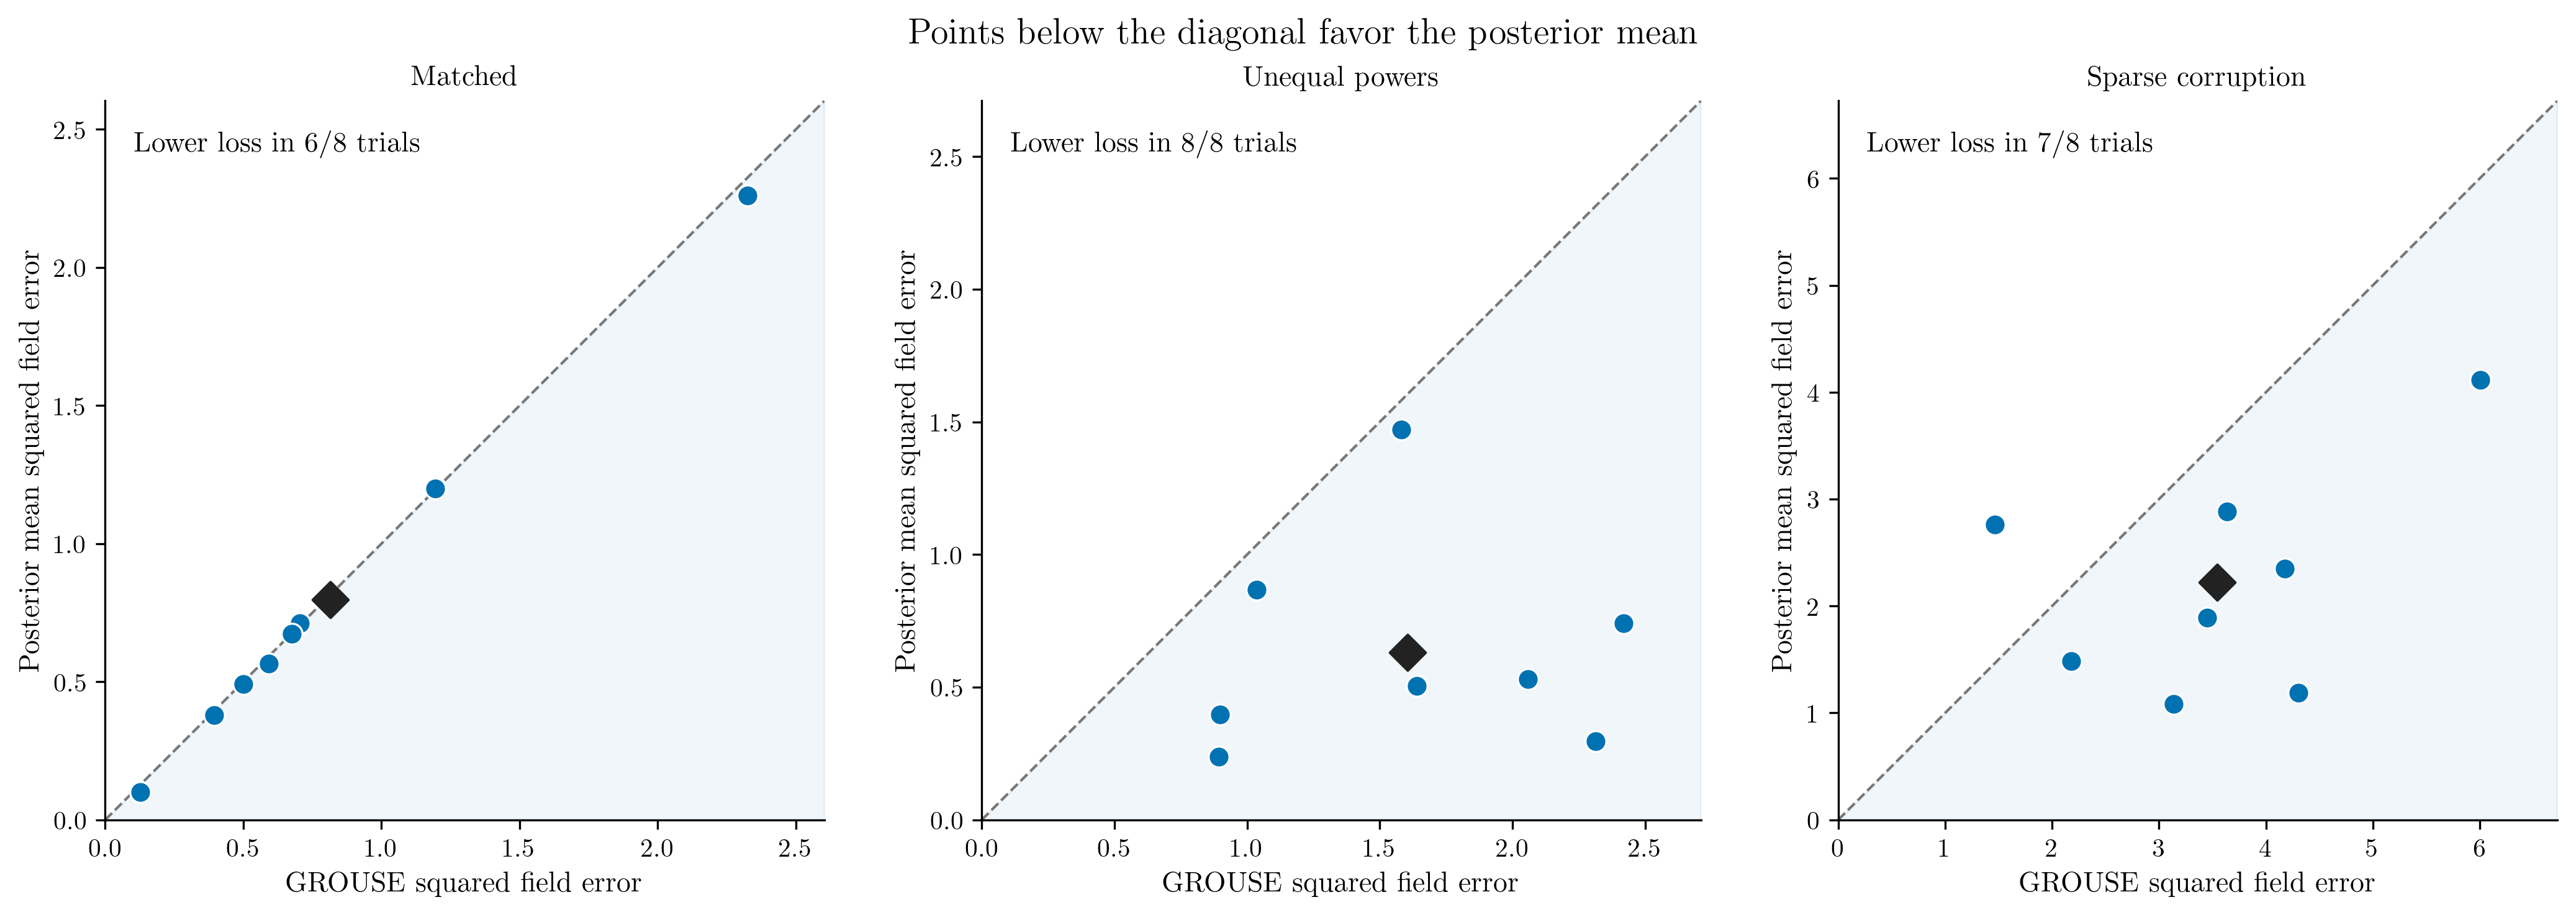

In [9]:
# Saved arrays/tables only; edit the plotting code below freely.
result = load_field_data(ROOT, 'application')
baseline = 'GROUSE'

DPI = 300
FIGSIZE = (14, 4.8)
SAVE_PDF = True

frame = _terminal(result['metrics'])
pairs = _pairs(frame, 'field_squared_error', baseline)
scenarios = [s for s in FIELD_SCENARIOS if s in frame.scenario.unique()]
fig, axs = plt.subplots(1, len(scenarios), figsize=FIGSIZE, dpi=DPI, layout='constrained', squeeze=False)
for ax, scenario in zip(axs.flat, scenarios):
    block = pairs.xs(scenario, level='scenario')
    x = block[baseline].to_numpy()
    y = block['Posterior mean'].to_numpy()
    lim = max(np.max(x), np.max(y)) * 1.12
    ax.fill_between([0, lim], [0, 0], [0, lim], color=COLORS['Posterior mean'], alpha=0.06)
    ax.plot([0, lim], [0, lim], color='#777777', ls='--', lw=1)
    ax.scatter(x, y, s=65, color=COLORS['Posterior mean'], edgecolor='white', lw=0.8, zorder=3)
    ax.scatter([x.mean()], [y.mean()], marker='D', s=95, color='#222222', zorder=4, label='Mean')
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel=f'{baseline} squared field error', ylabel='Posterior mean squared field error', title=scenario)
    ax.set_aspect('equal', adjustable='box')
    ax.text(0.04, 0.96, f'Lower loss in {int(np.sum(y < x))}/{len(x)} trials', transform=ax.transAxes, va='top', fontsize=11)
fig.suptitle('Points below the diagonal favor the posterior mean', fontsize=14)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_pairs.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

In [10]:
display(m[m.t==m.t.max()].groupby(['scenario','method']).field_squared_error.agg(['mean','std','count']))

mean       std  count
scenario          method                                   
Matched           EW PCA          0.798064  0.674097      8
                  GROUSE          0.814070  0.681799      8
                  Mode            0.798064  0.674097      8
                  Oracle          0.657018  0.491007      8
                  Posterior mean  0.797867  0.668895      8
                  Rolling PCA     0.720331  0.541698      8
Sparse corruption EW PCA          2.245619  1.010239      8
                  GROUSE          3.544295  1.384297      8
                  Mode            2.245619  1.010239      8
                  Oracle          1.591154  0.858507      8
                  Posterior mean  2.220881  1.024672      8
                  Rolling PCA     2.454236  1.208633      8
Unequal powers    EW PCA          0.644547  0.394583      8
                  GROUSE          1.605028  0.621244      8
                  Mode            0.644547  0.394583      8
                  Oracle          0.549981  0.463607      8
                  Posterior mean  0.630485  0.399751      8
                  Rolling PCA     0.605958  0.381743      8

### Inspect the spatial errors
The four field images share one amplitude scale. The two residual maps use a separate, common error scale, so spatial bias and smoothing are visible. This is one preassigned matched trajectory at the final observation, not a selected best reconstruction. Aggregate paired results above carry the comparison.

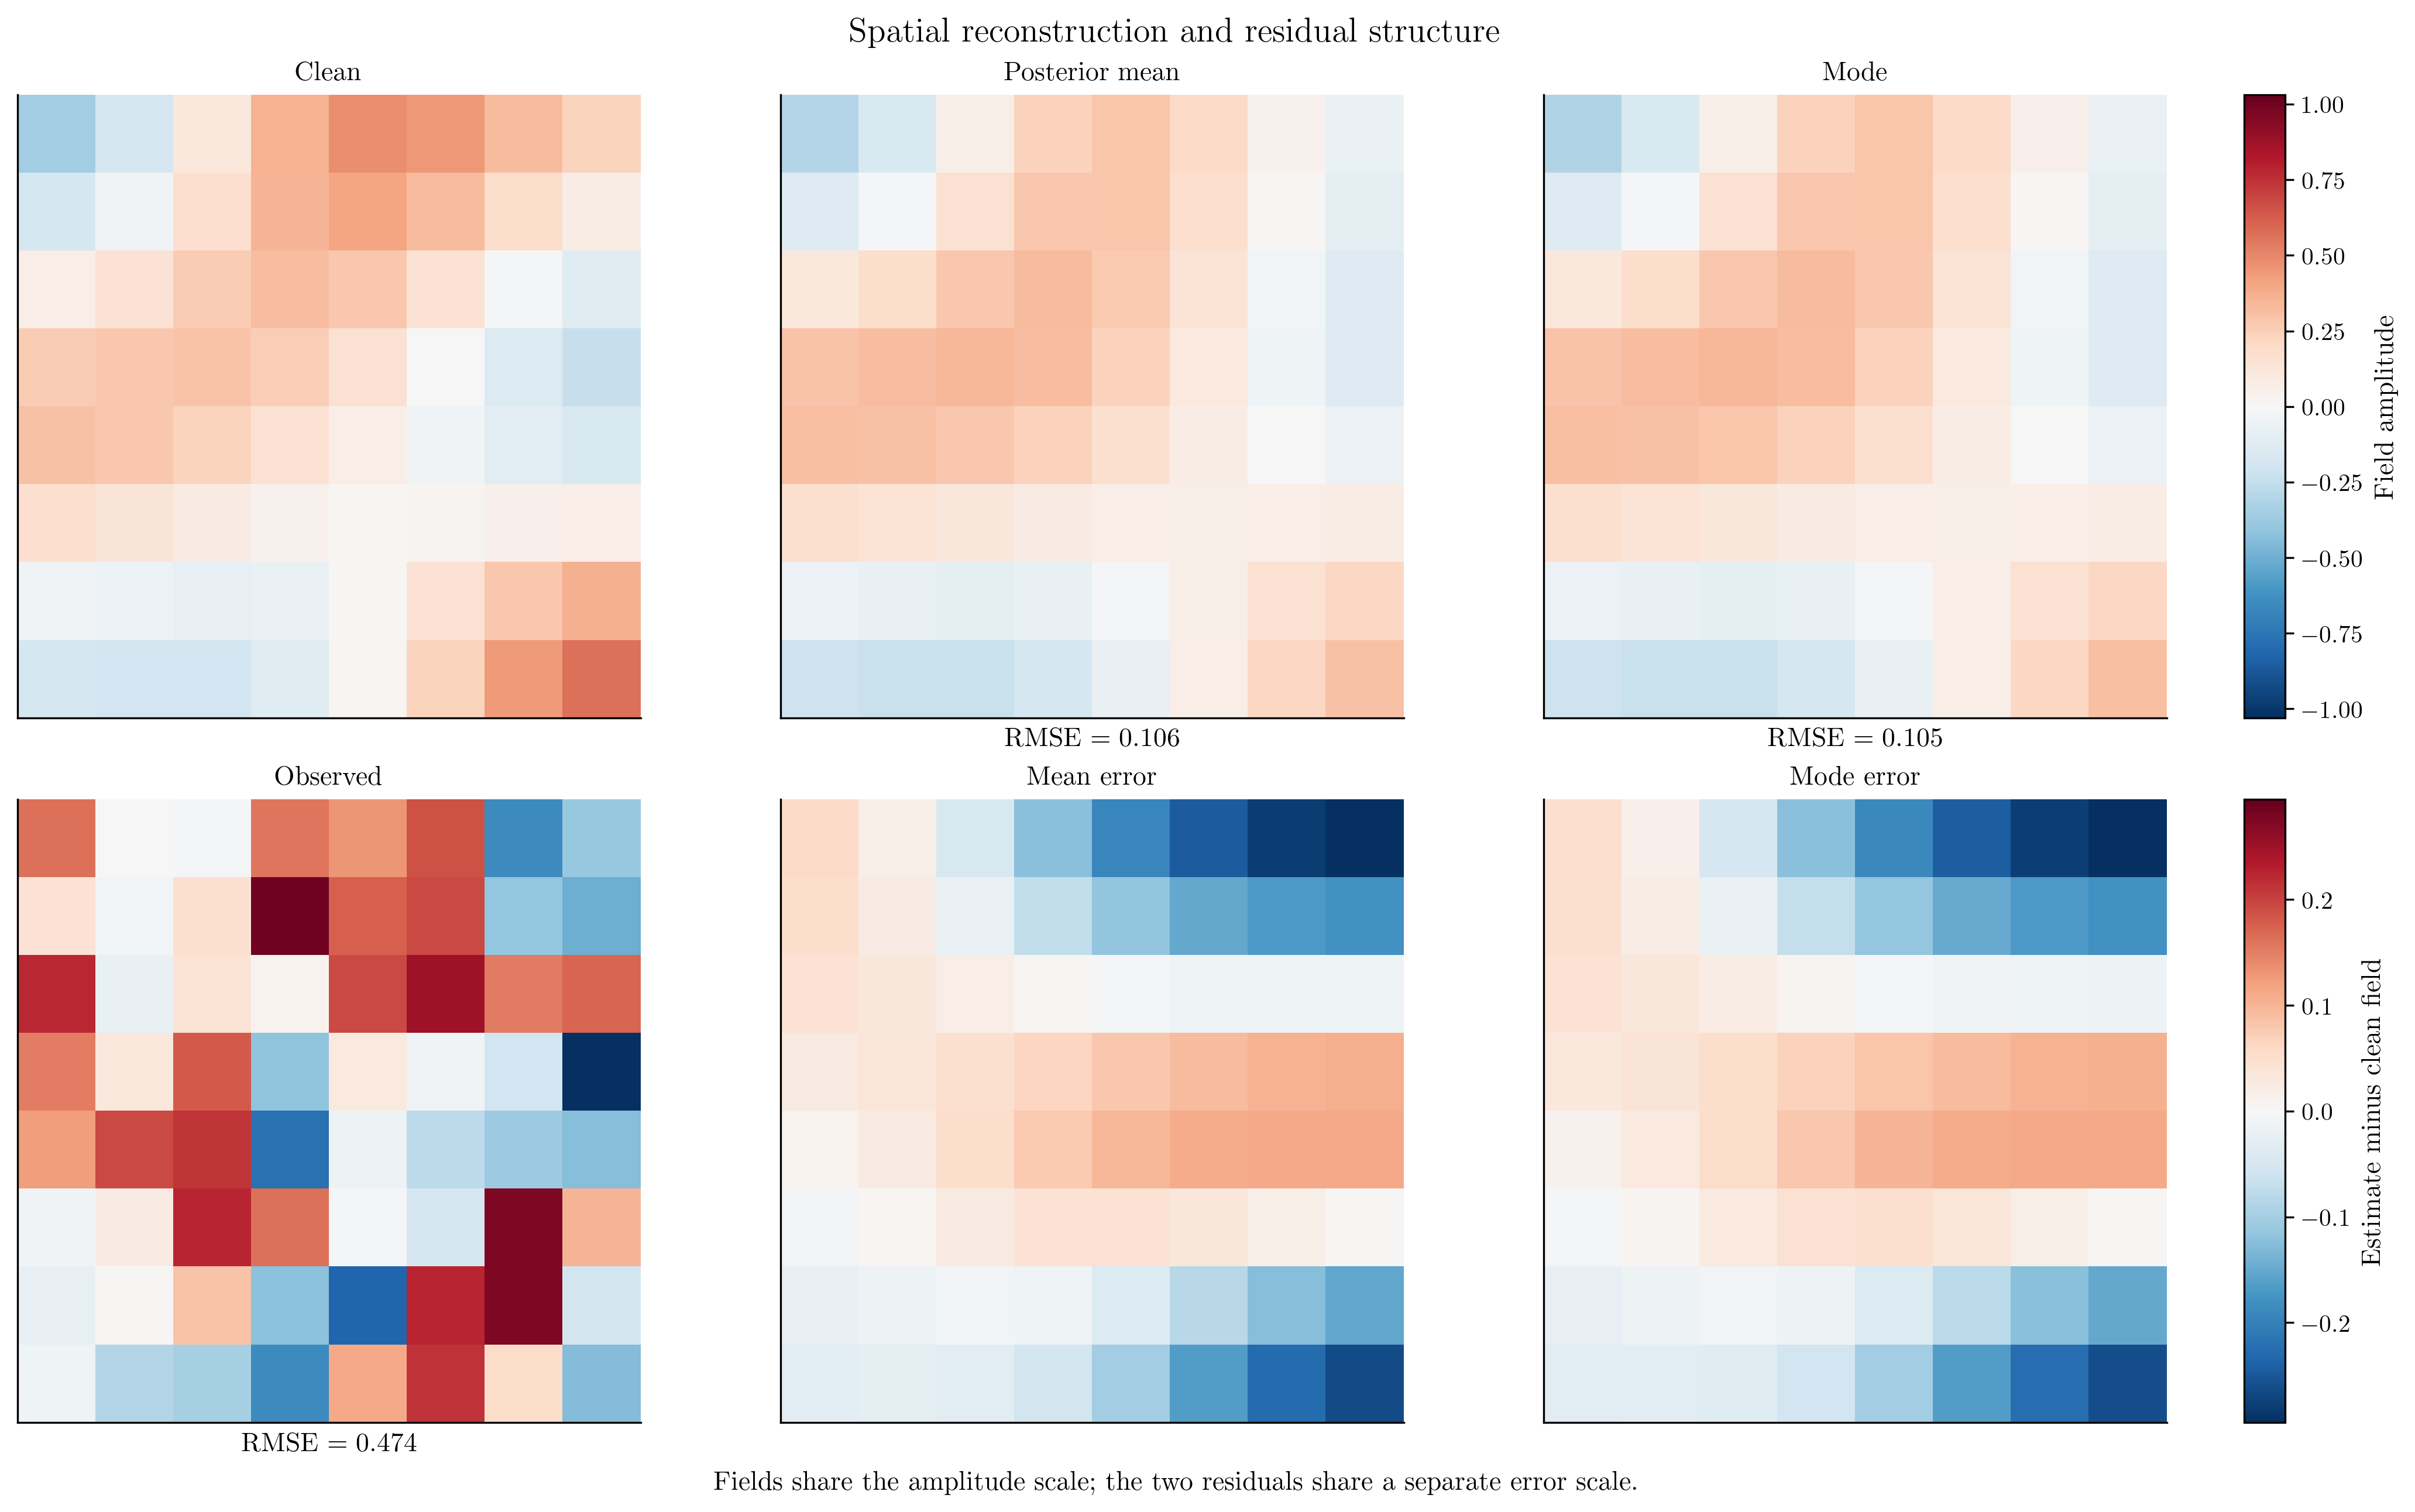

In [11]:
# Saved arrays/tables only; edit the plotting code below freely.
result = load_field_data(ROOT, 'application')

DPI = 300
FIGSIZE = (14, 8.5)
SAVE_PDF = True

f = result['fields'].sort_values(['row', 'column'])
fields = {name: np.asarray(f[name]).reshape(8, 8) for name in ['clean', 'observed', 'posterior_mean', 'mode']}
residuals = {name: fields[name] - fields['clean'] for name in ['posterior_mean', 'mode']}
amplitude = max((float(np.max(abs(v))) for v in fields.values()))
error = max((float(np.max(abs(v))) for v in residuals.values()))
fig = plt.figure(figsize=FIGSIZE, dpi=DPI, layout='constrained')
grid = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.055])
axs = np.array([[fig.add_subplot(grid[i, j]) for j in range(3)] for i in range(2)])
amplitude_bar = fig.add_subplot(grid[0, 3])
error_bar = fig.add_subplot(grid[1, 3])
items = [('clean', 'Clean'), ('posterior_mean', 'Posterior mean'), ('mode', 'Mode'), ('observed', 'Observed')]
field_axes = [axs[0, 0], axs[0, 1], axs[0, 2], axs[1, 0]]
for ax, (key, title) in zip(field_axes, items):
    im = ax.imshow(fields[key], cmap='RdBu_r', vmin=-amplitude, vmax=amplitude, interpolation='nearest')
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    if key != 'clean':
        rmse = np.sqrt(np.mean((fields[key] - fields['clean']) ** 2))
        ax.set_xlabel(f'RMSE $={rmse:.3f}$')
for ax, key, title in [(axs[1, 1], 'posterior_mean', 'Mean error'), (axs[1, 2], 'mode', 'Mode error')]:
    err = ax.imshow(residuals[key], cmap='RdBu_r', vmin=-error, vmax=error, interpolation='nearest')
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, cax=amplitude_bar, label='Field amplitude')
fig.colorbar(err, cax=error_bar, label='Estimate minus clean field')
fig.suptitle('Spatial reconstruction and residual structure', fontsize=14)
fig.supxlabel('Fields share the amplitude scale; the two residuals share a separate error scale.', fontsize=11)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_maps.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

### Known-input prediction is a different use of the posterior
Calibration inputs are preassigned independently of the hidden state and have transported ranks 6, 7, or 8. The left map measures realized response-error reduction against the mode. The right shows its nonnegative **posterior** excess risk from Eq. (30). The identity is conditional on a posterior; it does not require a realized true-state error ordering in every run.

These drifting paths do not test common-subspace global identifiability. The general theory notebook supplies the controlled ambiguity and excitation tests.

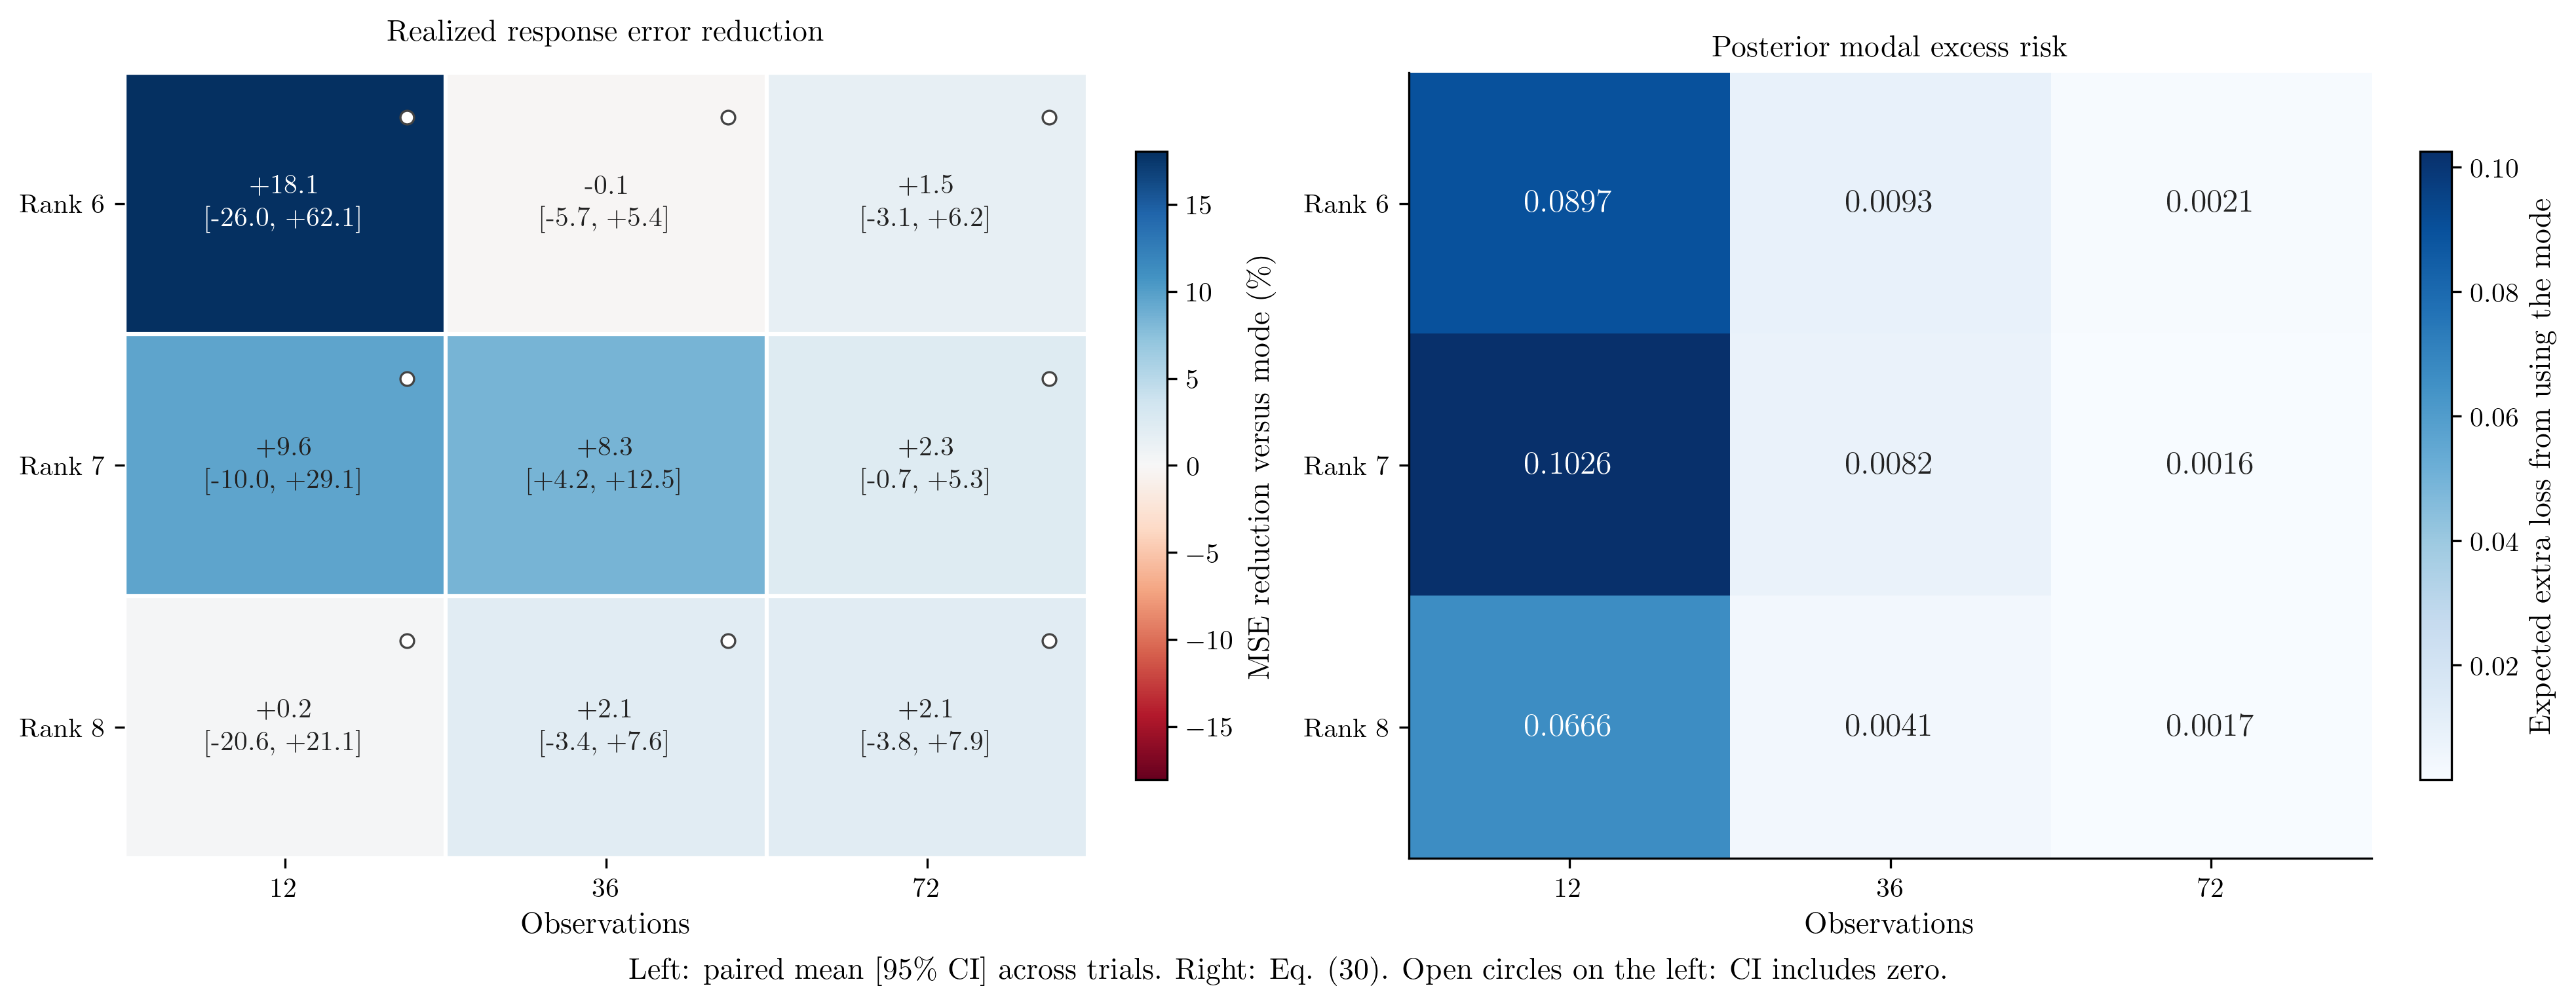

In [12]:
# Saved arrays/tables only; edit the plotting code below freely.
result = load_field_data(ROOT, 'application')

DPI = 300
FIGSIZE = (13, 5)
SAVE_PDF = True

c = result['calibration']
ranks = sorted(c.input_rank.unique())
times = sorted(c.t.unique())
gains = np.empty((len(ranks), len(times)))
low = gains.copy()
high = gains.copy()
excess = gains.copy()
for i, rank in enumerate(ranks):
    for j, time in enumerate(times):
        g = c[(c.input_rank == rank) & (c.t == time)]
        d = 100 * (g.modal_squared_error - g.mean_squared_error) / g.modal_squared_error.mean()
        gains[i, j], low[i, j], high[i, j] = _ci(d)
        excess[i, j] = g.modal_excess_risk.mean()
fig, axs = plt.subplots(1, 2, figsize=FIGSIZE, dpi=DPI, layout='constrained')
map1_ax = axs[0]
map1_means = gains
map1_low = low
map1_high = high
map1_rows = [f'Rank {r}' for r in ranks]
map1_columns = times
map1_title = 'Realized response error reduction'
map1_unit = '\\%'
map1_extent = None
map1_finite = np.abs(map1_means.ravel())
map1_finite = map1_finite[np.isfinite(map1_finite)]
map1_bound = max(float(map1_finite.max()) if map1_finite.size else 1.0, 1e-06) if map1_extent is None else map1_extent
map1_image = map1_ax.imshow(map1_means, cmap='RdBu', norm=TwoSlopeNorm(vmin=-map1_bound, vcenter=0, vmax=map1_bound), aspect='auto')
map1_ax.set_xticks(np.arange(len(map1_columns)), map1_columns)
map1_ax.set_yticks(np.arange(len(map1_rows)), map1_rows)
map1_ax.set_title(map1_title, pad=12)
for map1_i in range(len(map1_rows)):
    for map1_j in range(len(map1_columns)):
        if not np.isfinite(map1_means[map1_i, map1_j]):
            continue
        map1_color = 'white' if abs(map1_means[map1_i, map1_j]) > 0.55 * map1_bound else '#222222'
        map1_decimals = 2 if map1_unit == 'dB' else 1
        map1_label = f'{map1_means[map1_i, map1_j]:+.{map1_decimals}f}\n[{map1_low[map1_i, map1_j]:+.{map1_decimals}f}, {map1_high[map1_i, map1_j]:+.{map1_decimals}f}]'
        map1_ax.text(map1_j, map1_i, map1_label, ha='center', va='center', fontsize=10, color=map1_color, linespacing=1.35)
        if map1_low[map1_i, map1_j] <= 0 <= map1_high[map1_i, map1_j]:
            map1_ax.scatter(map1_j + 0.38, map1_i - 0.33, s=25, facecolors='white', edgecolors='#444444', linewidths=0.8, zorder=4)
map1_ax.set_xticks(np.arange(-0.5, len(map1_columns), 1), minor=True)
map1_ax.set_yticks(np.arange(-0.5, len(map1_rows), 1), minor=True)
map1_ax.grid(which='minor', color='white', linewidth=1.5)
map1_ax.tick_params(which='minor', bottom=False, left=False)
map1_ax.set_xlabel('Training snapshots' if map1_unit == 'dB' else 'Observations')
for map1_spine in map1_ax.spines.values():
    map1_spine.set_visible(False)
im = map1_image
fig.colorbar(im, ax=axs[0], shrink=0.8, label='MSE reduction versus mode (\\%)')
im = axs[1].imshow(excess, cmap='Blues', aspect='auto')
axs[1].set(xticks=range(len(times)), xticklabels=times, yticks=range(len(ranks)), yticklabels=[f'Rank {r}' for r in ranks], xlabel='Observations', title='Posterior modal excess risk')
for i in range(len(ranks)):
    for j in range(len(times)):
        axs[1].text(j, i, f'{excess[i, j]:.4f}', ha='center', va='center', fontsize=12, color='white' if excess[i, j] > 0.6 * excess.max() else '#222222')
fig.colorbar(im, ax=axs[1], shrink=0.8, label='Expected extra loss from using the mode')
fig.supxlabel('Left: paired mean [95\\% CI] across trials. Right: Eq. (30). Open circles on the left: CI includes zero.', fontsize=11)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_calibration.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

### Controlled prediction with identical information
A separate stationary real Gr(1,3) experiment tests the decision benefit under the actual Bayesian model. Every method receives the same passive training observations and fresh independent unit query vectors at decision time. No method is given hidden training inputs. Noise levels, rank, and prior-generating law are stated and shared.

The scalar-shrunk PCA control asks whether generic regularization is sufficient. GROUSE and shrinkage each receive the same number of independent validation candidates, separately per task and horizon. Posterior means use deterministic quadrature; all reported targets are checked against a higher order. All predeclared noise levels and horizons are shown, including ties or losses.

In [13]:
study = load_field_data(ROOT, 'decisions')
display(study['config'])
assert study['accuracy'].reference_difference.max() <= study['config']['tolerance']

{'seed': 86021,
 'trials': 400,
 'validation_trials': 160,
 'checkpoints': [1, 2, 4, 8, 16],
 'noise_levels': [1.0, 0.2],
 'tau2': 1.0,
 'n': 3,
 'k': 1,
 'query_directions_per_trial': 8,
 'steps': [0.02, 0.05, 0.08, 0.2, 0.35, 0.5, 1.0, 2.0, 4.0],
 'rhos': [0.0, 0.1, 0.25, 0.4, 0.55, 0.7, 0.85, 0.95, 1.0],
 'loadings': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 1000000.0],
 'candidate_count': 9,
 'coverage_trials_per_regime': 100,
 'coverage_mass': 0.95,
 'calibration_protocol': 'Exact joint Haar prior, stationary state and Gaussian likelihood; predeclared first coverage_trials trajectories at terminal time; not robustness under drift',
 'quadrature_order': 48,
 'reference_order': 96,
 'tolerance': 1e-08,
 'projection_protocol': 'Same passive observations; fresh independent unit queries supplied to every method at decision time',
 'reconstruction_protocol': 'Same current observation; known noise; Prior mean uses isotropic LMMSE, other methods use conditional Wiener shrinkage',
 'bea

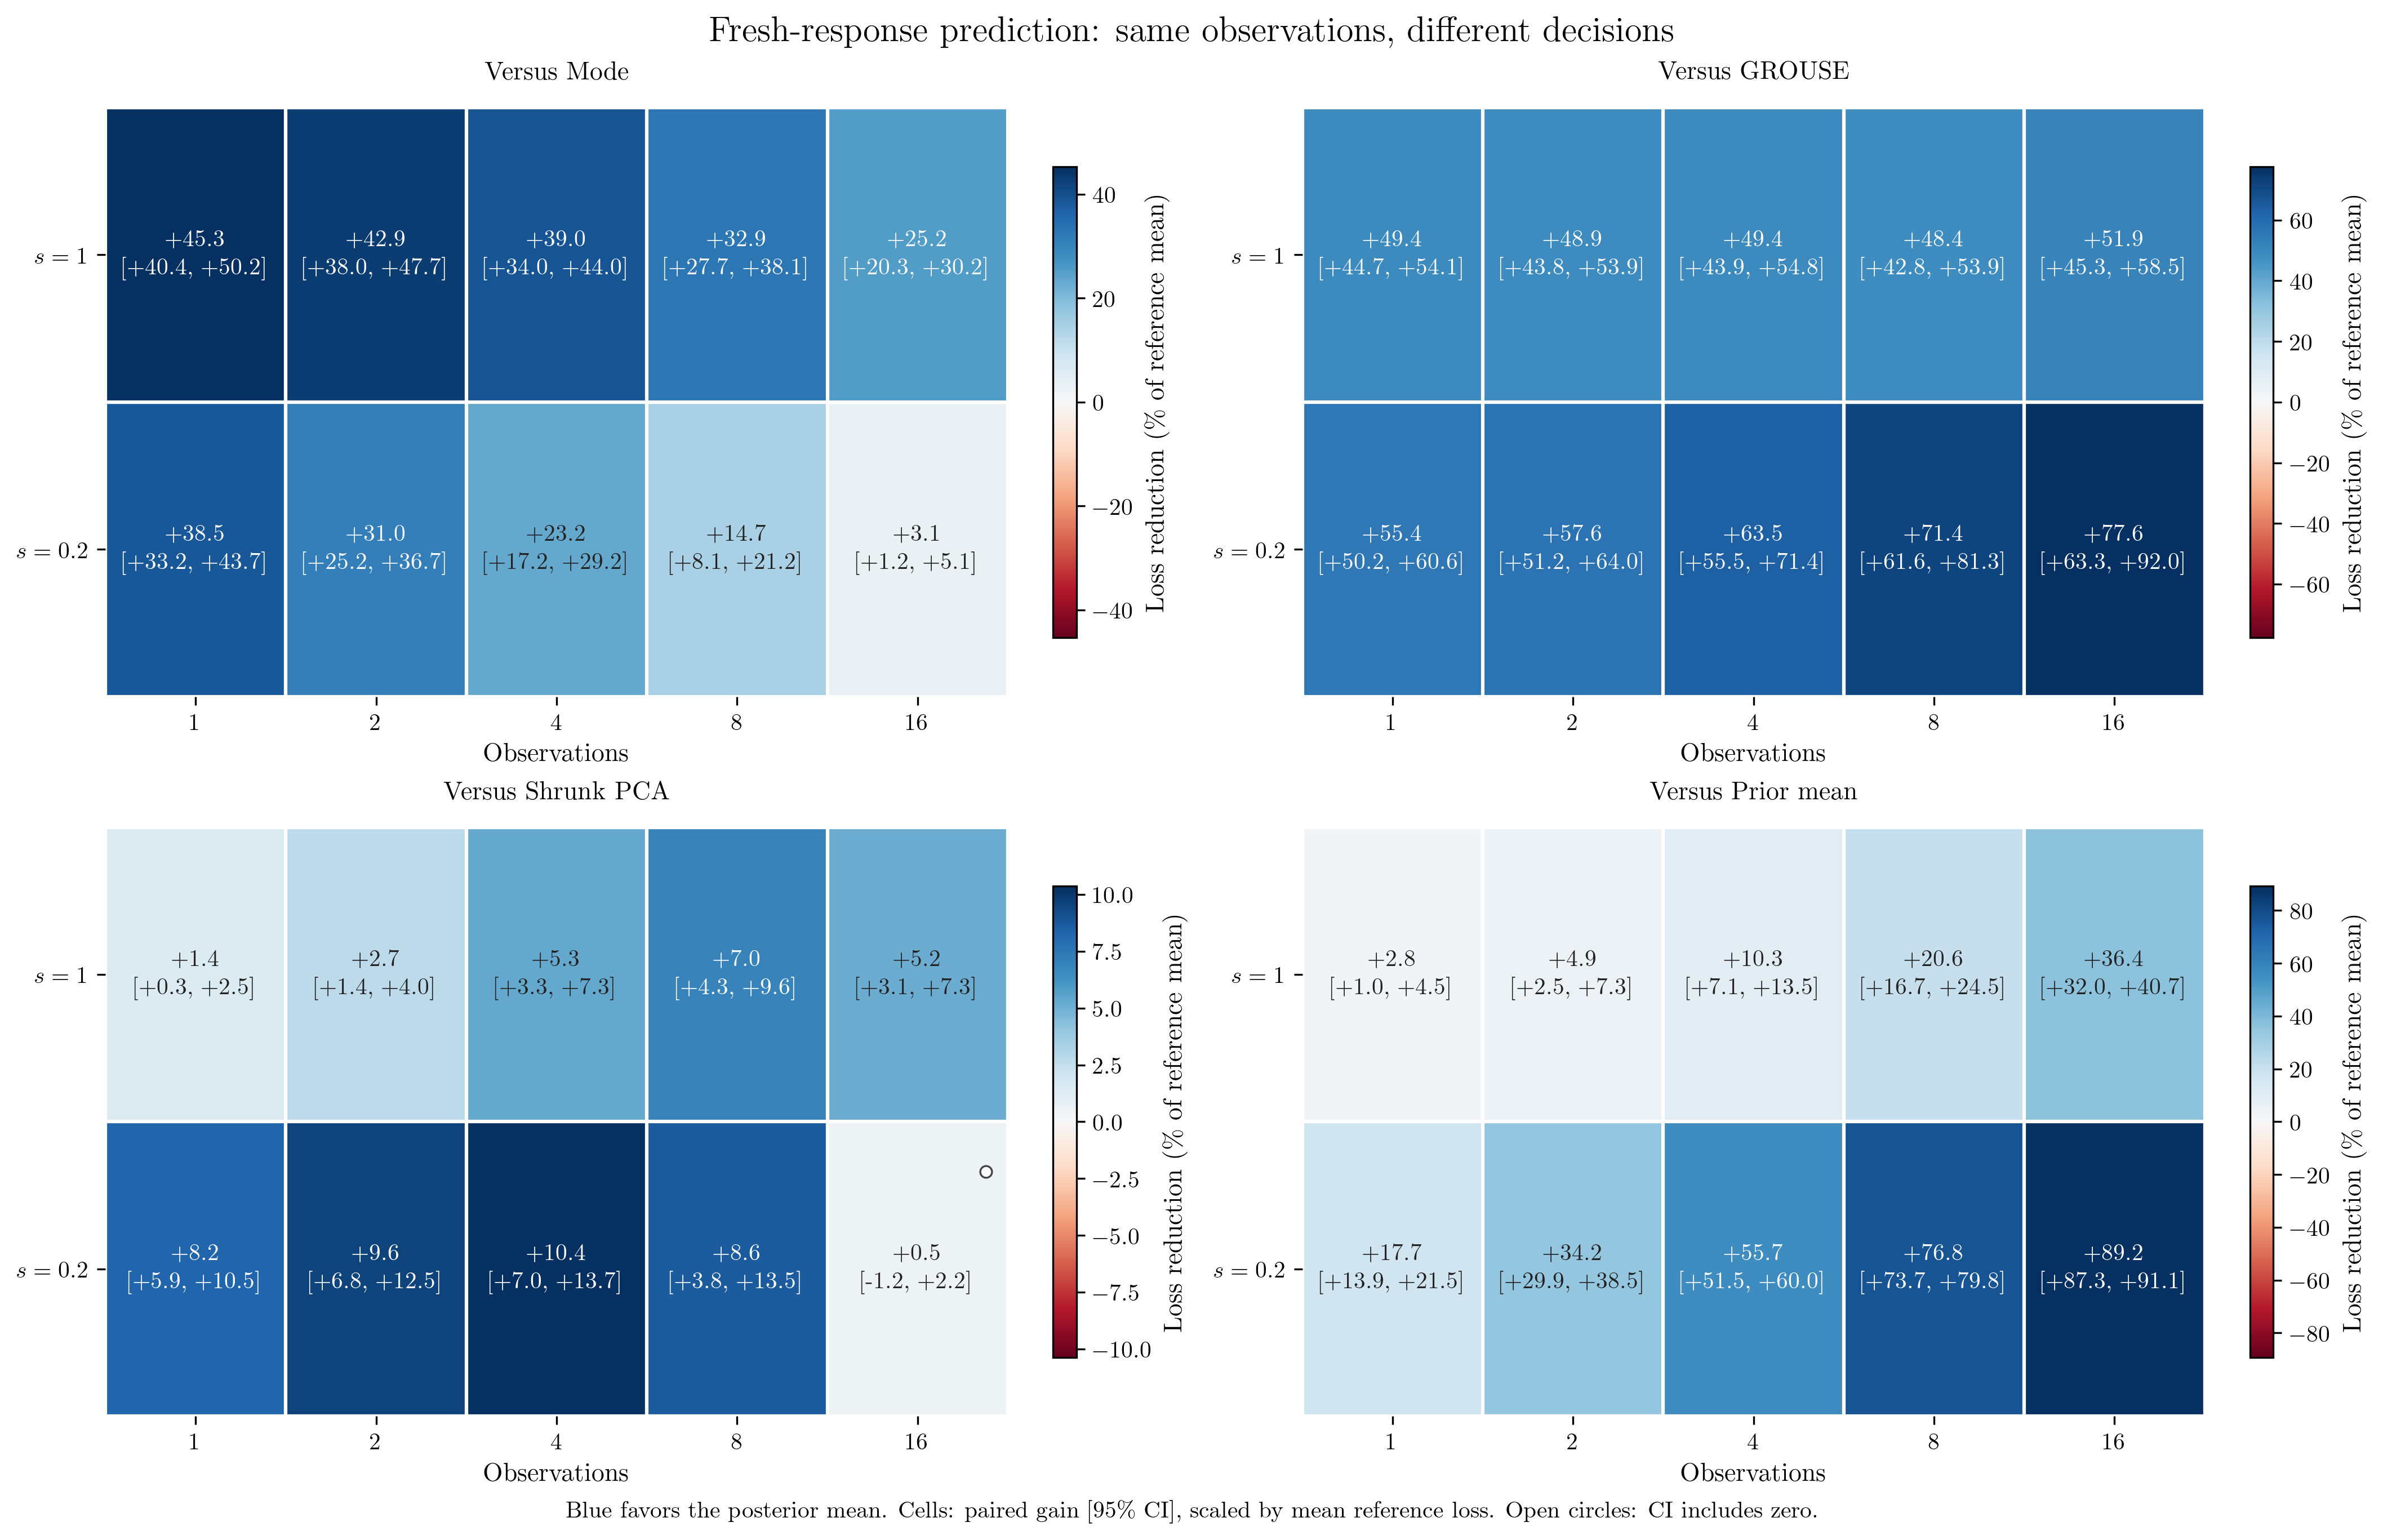

In [14]:
# Saved arrays/tables only; edit the plotting code below freely.
study = load_field_data(ROOT, 'decisions')
task = 'Projection'

DPI = 300
FIGSIZE = (14, 9)
SAVE_PDF = True

table = study['paired']
table = table[table.task == task]
references = ['Mode', 'GROUSE', 'Shrunk PCA', 'Loaded covariance' if task == 'Beamforming' else 'Prior mean']
noises = study['config']['noise_levels']
times = study['config']['checkpoints']
fig, axs = plt.subplots(2, 2, figsize=FIGSIZE, dpi=DPI, layout='constrained')
for ax, reference in zip(axs.flat, references):
    mean = np.full((len(noises), len(times)), np.nan)
    low = mean.copy()
    high = mean.copy()
    for i, _ in enumerate(noises):
        for j, time in enumerate(times):
            row = table[(table.regime == i) & (table.t == time) & (table.reference == reference)]
            if row.empty:
                continue
            row = row.iloc[0]
            scale = 100 / row.baseline_loss
            mean[i, j] = row.paired_gain * scale
            low[i, j] = row.gain_low * scale
            high[i, j] = row.gain_high * scale
    map1_ax = ax
    map1_means = mean
    map1_low = low
    map1_high = high
    map1_rows = [f'$s={s:g}$' for s in noises]
    map1_columns = times
    map1_title = f'Versus {reference}'
    map1_unit = '\\%'
    map1_extent = None
    map1_finite = np.abs(map1_means.ravel())
    map1_finite = map1_finite[np.isfinite(map1_finite)]
    map1_bound = max(float(map1_finite.max()) if map1_finite.size else 1.0, 1e-06) if map1_extent is None else map1_extent
    map1_image = map1_ax.imshow(map1_means, cmap='RdBu', norm=TwoSlopeNorm(vmin=-map1_bound, vcenter=0, vmax=map1_bound), aspect='auto')
    map1_ax.set_xticks(np.arange(len(map1_columns)), map1_columns)
    map1_ax.set_yticks(np.arange(len(map1_rows)), map1_rows)
    map1_ax.set_title(map1_title, pad=12)
    for map1_i in range(len(map1_rows)):
        for map1_j in range(len(map1_columns)):
            if not np.isfinite(map1_means[map1_i, map1_j]):
                continue
            map1_color = 'white' if abs(map1_means[map1_i, map1_j]) > 0.55 * map1_bound else '#222222'
            map1_decimals = 2 if map1_unit == 'dB' else 1
            map1_label = f'{map1_means[map1_i, map1_j]:+.{map1_decimals}f}\n[{map1_low[map1_i, map1_j]:+.{map1_decimals}f}, {map1_high[map1_i, map1_j]:+.{map1_decimals}f}]'
            map1_ax.text(map1_j, map1_i, map1_label, ha='center', va='center', fontsize=10, color=map1_color, linespacing=1.35)
            if map1_low[map1_i, map1_j] <= 0 <= map1_high[map1_i, map1_j]:
                map1_ax.scatter(map1_j + 0.38, map1_i - 0.33, s=25, facecolors='white', edgecolors='#444444', linewidths=0.8, zorder=4)
    map1_ax.set_xticks(np.arange(-0.5, len(map1_columns), 1), minor=True)
    map1_ax.set_yticks(np.arange(-0.5, len(map1_rows), 1), minor=True)
    map1_ax.grid(which='minor', color='white', linewidth=1.5)
    map1_ax.tick_params(which='minor', bottom=False, left=False)
    map1_ax.set_xlabel('Training snapshots' if map1_unit == 'dB' else 'Observations')
    for map1_spine in map1_ax.spines.values():
        map1_spine.set_visible(False)
    im = map1_image
    fig.colorbar(im, ax=ax, shrink=0.8, label='Loss reduction (\\% of reference mean)')
title = {'Projection': 'Fresh-response prediction', 'Reconstruction': 'Current-vector reconstruction', 'Beamforming': 'Interference power'}[task]
fig.suptitle(title + ': same observations, different decisions', fontsize=15)
fig.supxlabel('Blue favors the posterior mean. Cells: paired gain [95\\% CI], scaled by mean reference loss. Open circles: CI includes zero.', fontsize=10)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_low_data_prediction.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

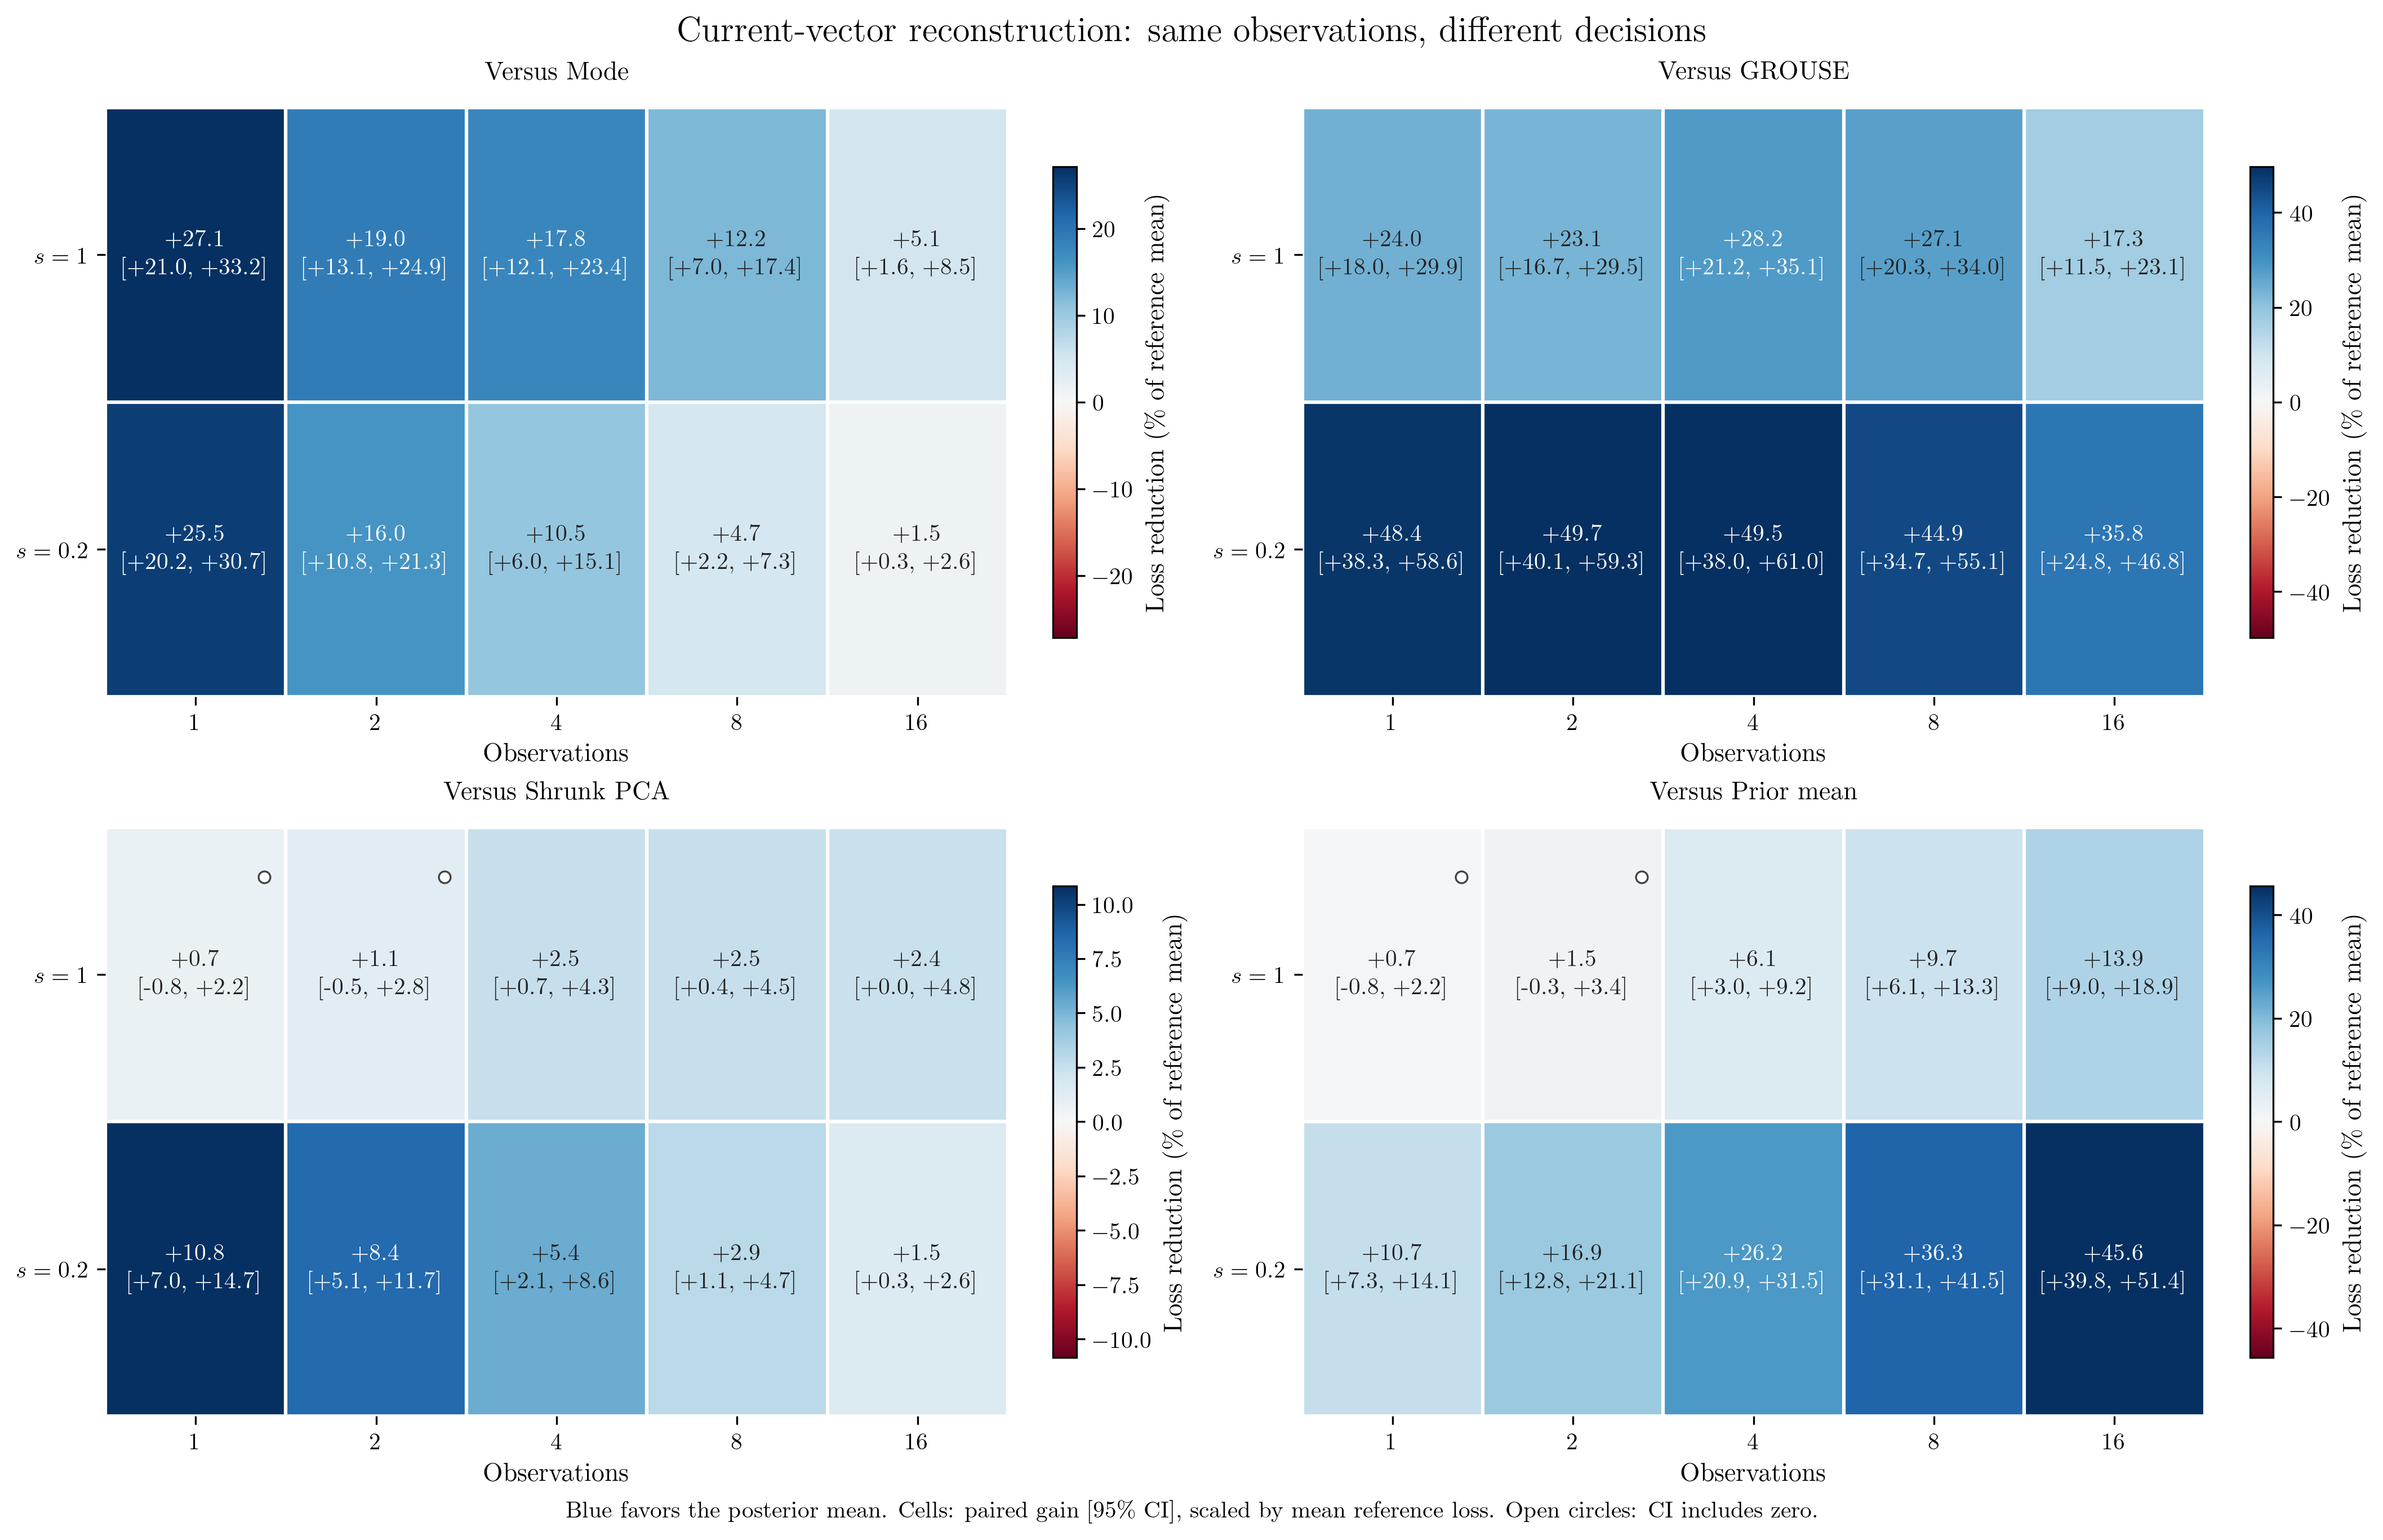

In [15]:
# Saved arrays/tables only; edit the plotting code below freely.
study = load_field_data(ROOT, 'decisions')
task = 'Reconstruction'

DPI = 300
FIGSIZE = (14, 9)
SAVE_PDF = True

table = study['paired']
table = table[table.task == task]
references = ['Mode', 'GROUSE', 'Shrunk PCA', 'Loaded covariance' if task == 'Beamforming' else 'Prior mean']
noises = study['config']['noise_levels']
times = study['config']['checkpoints']
fig, axs = plt.subplots(2, 2, figsize=FIGSIZE, dpi=DPI, layout='constrained')
for ax, reference in zip(axs.flat, references):
    mean = np.full((len(noises), len(times)), np.nan)
    low = mean.copy()
    high = mean.copy()
    for i, _ in enumerate(noises):
        for j, time in enumerate(times):
            row = table[(table.regime == i) & (table.t == time) & (table.reference == reference)]
            if row.empty:
                continue
            row = row.iloc[0]
            scale = 100 / row.baseline_loss
            mean[i, j] = row.paired_gain * scale
            low[i, j] = row.gain_low * scale
            high[i, j] = row.gain_high * scale
    map1_ax = ax
    map1_means = mean
    map1_low = low
    map1_high = high
    map1_rows = [f'$s={s:g}$' for s in noises]
    map1_columns = times
    map1_title = f'Versus {reference}'
    map1_unit = '\\%'
    map1_extent = None
    map1_finite = np.abs(map1_means.ravel())
    map1_finite = map1_finite[np.isfinite(map1_finite)]
    map1_bound = max(float(map1_finite.max()) if map1_finite.size else 1.0, 1e-06) if map1_extent is None else map1_extent
    map1_image = map1_ax.imshow(map1_means, cmap='RdBu', norm=TwoSlopeNorm(vmin=-map1_bound, vcenter=0, vmax=map1_bound), aspect='auto')
    map1_ax.set_xticks(np.arange(len(map1_columns)), map1_columns)
    map1_ax.set_yticks(np.arange(len(map1_rows)), map1_rows)
    map1_ax.set_title(map1_title, pad=12)
    for map1_i in range(len(map1_rows)):
        for map1_j in range(len(map1_columns)):
            if not np.isfinite(map1_means[map1_i, map1_j]):
                continue
            map1_color = 'white' if abs(map1_means[map1_i, map1_j]) > 0.55 * map1_bound else '#222222'
            map1_decimals = 2 if map1_unit == 'dB' else 1
            map1_label = f'{map1_means[map1_i, map1_j]:+.{map1_decimals}f}\n[{map1_low[map1_i, map1_j]:+.{map1_decimals}f}, {map1_high[map1_i, map1_j]:+.{map1_decimals}f}]'
            map1_ax.text(map1_j, map1_i, map1_label, ha='center', va='center', fontsize=10, color=map1_color, linespacing=1.35)
            if map1_low[map1_i, map1_j] <= 0 <= map1_high[map1_i, map1_j]:
                map1_ax.scatter(map1_j + 0.38, map1_i - 0.33, s=25, facecolors='white', edgecolors='#444444', linewidths=0.8, zorder=4)
    map1_ax.set_xticks(np.arange(-0.5, len(map1_columns), 1), minor=True)
    map1_ax.set_yticks(np.arange(-0.5, len(map1_rows), 1), minor=True)
    map1_ax.grid(which='minor', color='white', linewidth=1.5)
    map1_ax.tick_params(which='minor', bottom=False, left=False)
    map1_ax.set_xlabel('Training snapshots' if map1_unit == 'dB' else 'Observations')
    for map1_spine in map1_ax.spines.values():
        map1_spine.set_visible(False)
    im = map1_image
    fig.colorbar(im, ax=ax, shrink=0.8, label='Loss reduction (\\% of reference mean)')
title = {'Projection': 'Fresh-response prediction', 'Reconstruction': 'Current-vector reconstruction', 'Beamforming': 'Interference power'}[task]
fig.suptitle(title + ': same observations, different decisions', fontsize=15)
fig.supxlabel('Blue favors the posterior mean. Cells: paired gain [95\\% CI], scaled by mean reference loss. Open circles: CI includes zero.', fontsize=10)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_low_data_reconstruction.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

In [16]:
display(study['paired'][(study['paired'].task=='Projection')&study['paired'].t.isin([1,4,16])][['regime','t','reference','baseline_loss','posterior_loss','reduction_percent','gain_low','gain_high']])

,regime,t,reference,baseline_loss,posterior_loss,reduction_percent,gain_low,gain_high
0,0,1,EW PCA,0.391274,0.213998,45.307486,0.158197,0.196355
1,0,1,GROUSE,0.422836,0.213998,49.389995,0.188809,0.228869
2,0,1,Mode,0.391274,0.213998,45.307486,0.158197,0.196355
3,0,1,Oracle,0.000000,0.213998,NaN,-0.219038,-0.208957
4,0,1,Prior mean,0.220091,0.213998,2.768558,0.002257,0.009930
5,0,1,Shrunk PCA,0.217046,0.213998,1.404608,0.000587,0.005510
38,0,4,EW PCA,0.323769,0.197477,39.006788,0.110003,0.142581
39,0,4,GROUSE,0.389908,0.197477,49.352985,0.171218,0.213645
40,0,4,Mode,0.323769,0.197477,39.006788,0.110003,0.142581
41,0,4,Oracle,0.000000,0.197477,NaN,-0.204881,-0.190072


### Calibrated under the model does not mean robust to drift
The controlled experiment's coverage panel uses the first predeclared trajectories at the terminal time and continuous-CDF region thresholds. Its risk panel bins independent terminal trajectories by predicted risk and compares them with observed loss.

The application coverage below is a different evaluation law: it contains unmodelled motion and approximate forgetting. In the original matched-covariance field run, both nominal 95% regions have 0/8 terminal coverage. This contrast identifies the state-model limitation; it is not a claim that point trackers intrinsically provide competing credible regions.

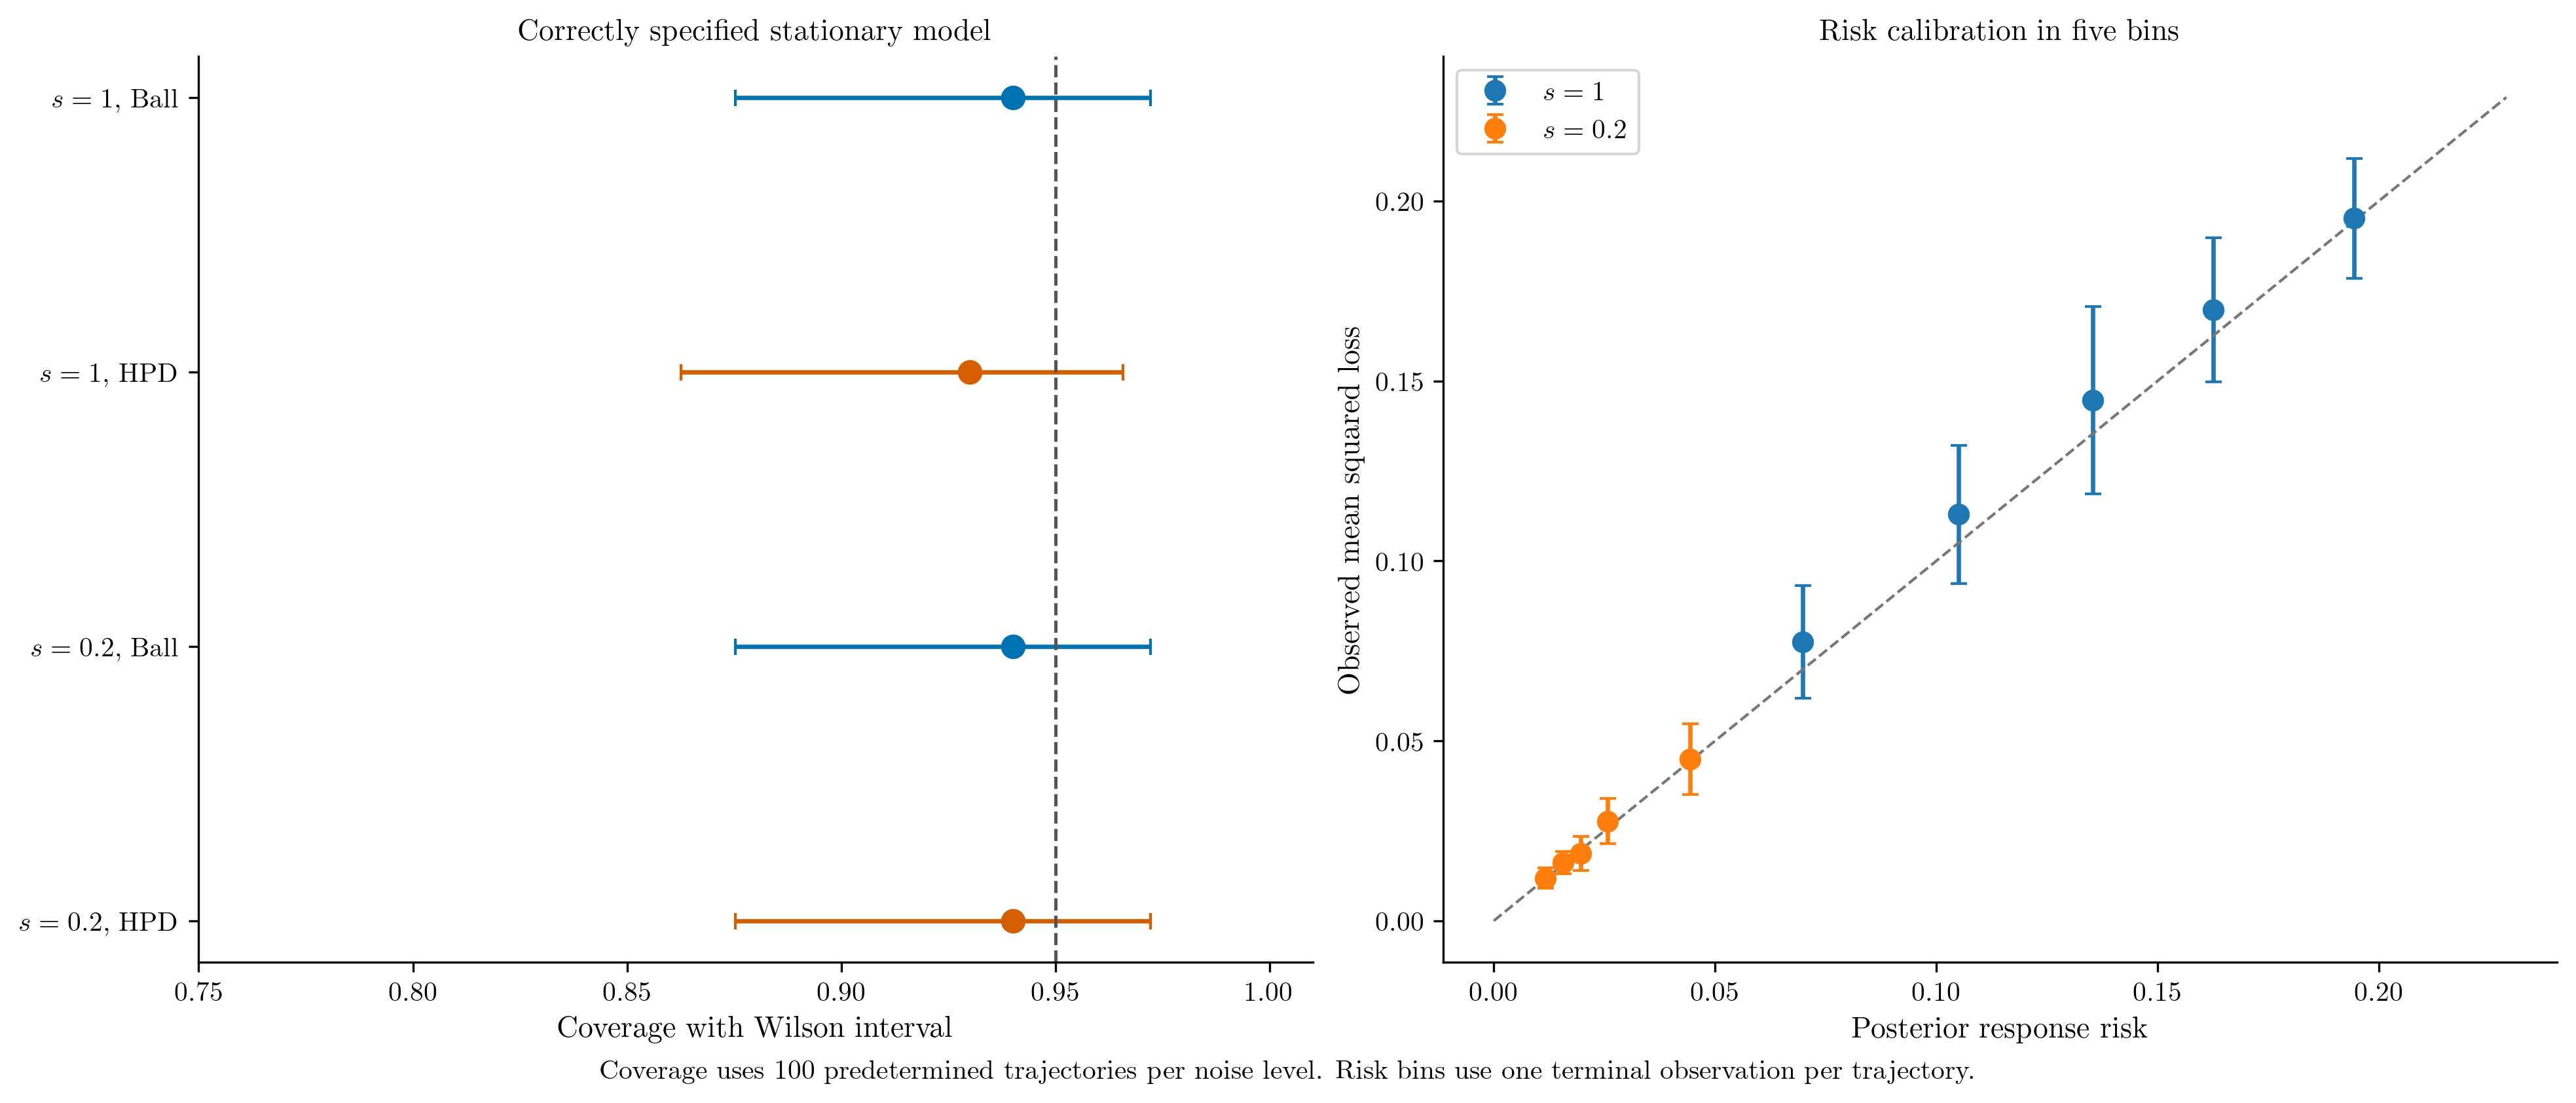

In [17]:
# Saved arrays/tables only; edit the plotting code below freely.
study = load_field_data(ROOT, 'decisions')

DPI = 300
FIGSIZE = (13, 5.5)
SAVE_PDF = True

coverage = study['coverage']
metrics = study['metrics']
noises = study['config']['noise_levels']
fig, axs = plt.subplots(1, 2, figsize=FIGSIZE, dpi=DPI, layout='constrained')
positions = []
labels = []
position = 0
for regime, s in enumerate(noises):
    g = coverage[coverage.regime == regime]
    for region, column in [('Ball', 'ball_covered'), ('HPD', 'hpd_covered')]:
        n = len(g)
        p = g[column].astype(bool).mean()
        low, high = wilson(int(g[column].astype(bool).sum()), n)
        axs[0].errorbar(p, position, xerr=[[max(0, p - low)], [max(0, high - p)]], fmt='o', ms=8, capsize=3, color=COLORS[region])
        positions.append(position)
        labels.append(f'$s={s:g}$, {region}')
        position += 1
axs[0].axvline(0.95, color='#555555', ls='--', lw=1.2)
axs[0].set(yticks=positions, yticklabels=labels, xlim=(0.75, 1.01), xlabel='Coverage with Wilson interval', title='Correctly specified stationary model')
axs[0].invert_yaxis()
p = metrics[(metrics.method == 'Posterior mean') & (metrics.t == metrics.t.max())]
upper = 0.0
for regime, s in enumerate(noises):
    g = p[p.regime == regime].copy()
    g['bin'] = pd.qcut(g.posterior_risk, 5, labels=False, duplicates='drop')
    rows = []
    for _, b in g.groupby('bin'):
        x = b.posterior_risk.mean()
        y = b.projection_loss.mean()
        ci = student_t.ppf(0.975, len(b) - 1) * b.projection_loss.std(ddof=1) / np.sqrt(len(b))
        rows.append((x, y, ci))
        upper = max(upper, x, y + ci)
    a = np.asarray(rows)
    axs[1].errorbar(a[:, 0], a[:, 1], yerr=a[:, 2], fmt='o', ms=7, capsize=3, label=f'$s={s:g}$')
axs[1].plot([0, upper * 1.08], [0, upper * 1.08], '--', color='#777777', lw=1)
axs[1].set(xlabel='Posterior response risk', ylabel='Observed mean squared loss', title='Risk calibration in five bins')
axs[1].legend()
counts = coverage.groupby('regime').size()
fig.supxlabel(f'Coverage uses {int(counts.min())} predetermined trajectories per noise level. Risk bins use one terminal observation per trajectory.', fontsize=10)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_model_calibration.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

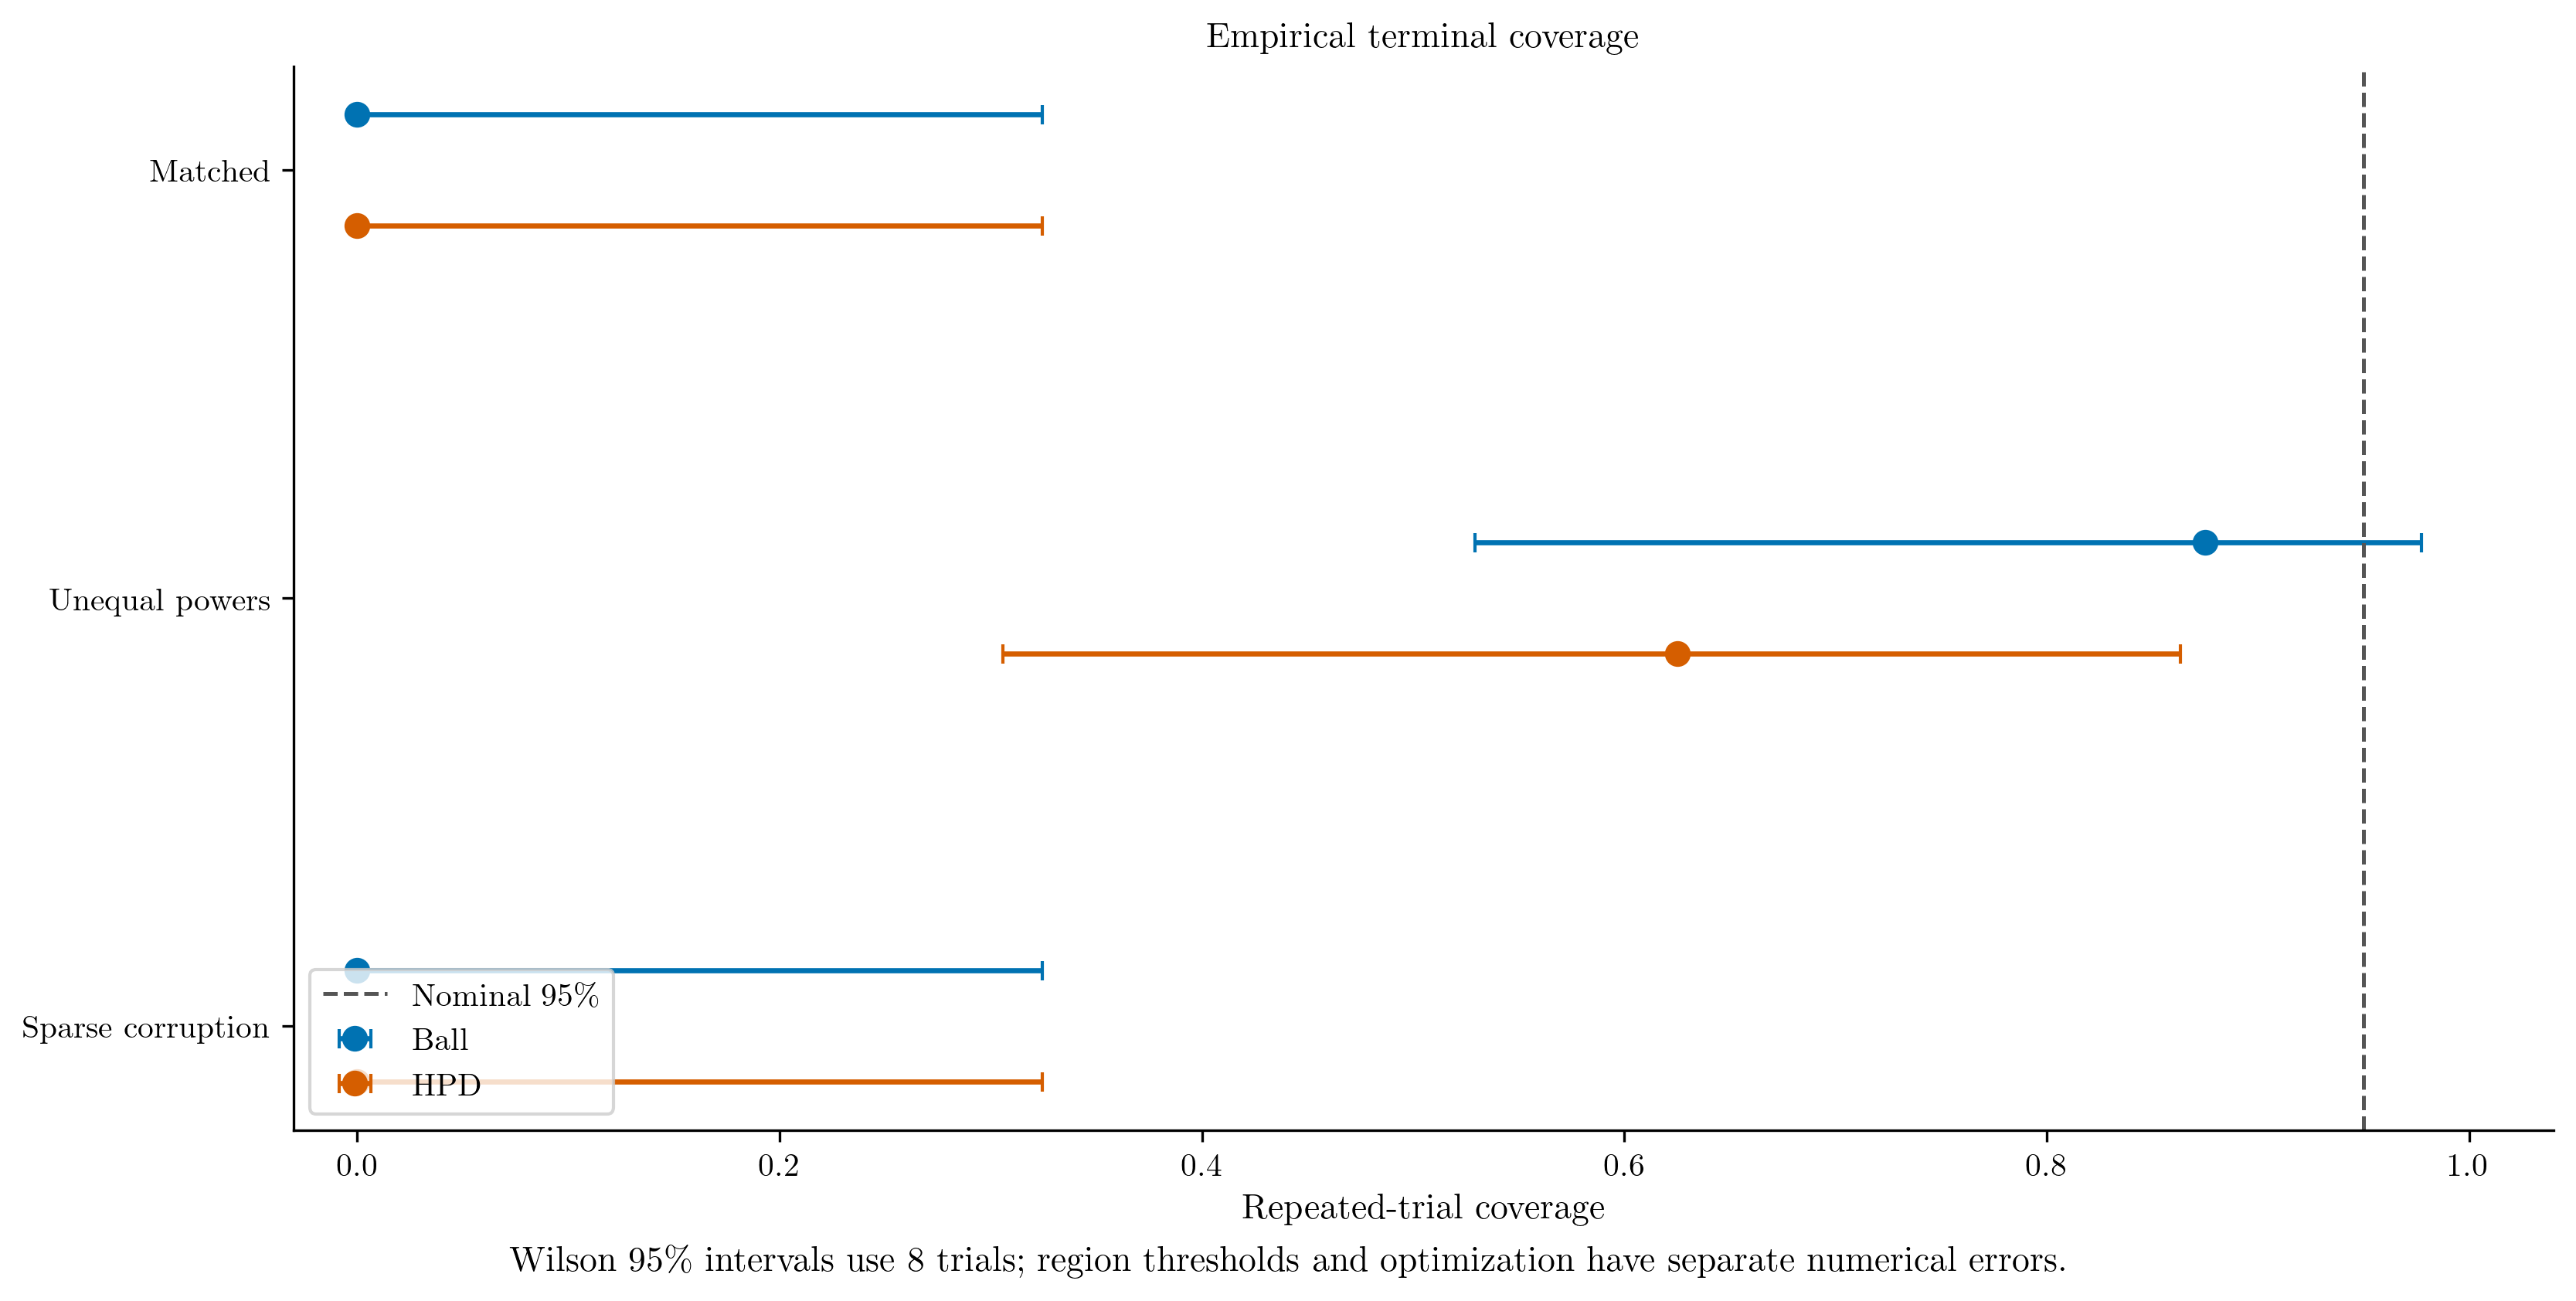

In [18]:
# Saved arrays/tables only; edit the plotting code below freely.
result = load_field_data(ROOT, 'application')
array = False

DPI = 300
FIGSIZE = (14, 7) if array else (11, 5.5)
SAVE_PDF = True

frame = _terminal(result['metrics'])
p = frame[frame.method == 'Posterior mean']
scenarios = [s for s in (ARRAY_SCENARIOS if array else FIELD_SCENARIOS) if s in p.scenario.unique()]
table = coverage_table(p)
fig, axs = plt.subplots(1, 2 if array else 1, figsize=FIGSIZE, dpi=DPI, layout='constrained', squeeze=False)
ax = axs[0, 0]
positions = np.arange(len(scenarios))
for region, offset in [('Ball', -0.13), ('HPD', 0.13)]:
    g = table[table.region == region].set_index('scenario').reindex(scenarios)
    ax.errorbar(g.coverage, positions + offset, xerr=np.maximum(0, [g.coverage - g.low, g.high - g.coverage]), fmt='o', ms=7, capsize=3, color=COLORS[region], label=region)
ax.axvline(0.95, color='#555555', ls='--', lw=1.2, label='Nominal 95\\%')
ax.set(yticks=positions, yticklabels=scenarios, xlim=(-0.03, 1.04), xlabel='Repeated-trial coverage', title='Empirical terminal coverage')
ax.invert_yaxis()
ax.legend(loc='lower left', fontsize=10)
if array:
    r = _terminal(result['regions'])
    pair = r.pivot(index=['scenario', 'repeat'], columns='region', values='upper')
    ax = axs[0, 1]
    for i, scenario in enumerate(scenarios):
        block = pair.xs(scenario, level='scenario')
        ratios = block.HPD / block.Ball
        offsets = np.linspace(-0.09, 0.09, len(ratios))
        ax.scatter(ratios, i + offsets, s=34, color=COLORS['Posterior mean'], alpha=0.65)
        ax.scatter([ratios.median()], [i], s=85, marker='D', color='#222222', zorder=3)
    ax.axvline(1, color='#555555', ls='--', lw=1.2)
    ax.set(yticks=positions, yticklabels=scenarios, xlabel='HPD / ball leakage bound', title='Directional leakage bounds')
    ax.invert_yaxis()
    ax.text(0.02, 0.01, 'Each dot is one trial; diamonds are medians', transform=ax.transAxes, fontsize=10)
fig.supxlabel(f'Wilson 95\\% intervals use {p.repeat.nunique()} trials; region thresholds and optimization have separate numerical errors.', fontsize=11)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_regions.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

### Noise estimation needs the uncertainty term
Separate fits use eight stored priors and two EM iterations. The stacked bars decompose the same window residual statistic into the residual of the mean response and the nonnegative subspace-uncertainty term. Treating the mean residual alone as the variance statistic omits that term.

Sampled high-dimensional EM ascent remains unverified. Predictive scores are recorded before fitting and assimilation, with Gaussian constants retained. Different cells correspond to different incoming observations; an increasing log score is not evidence of ascent of one fixed objective. Importance ESS and sampler ESS answer different questions.

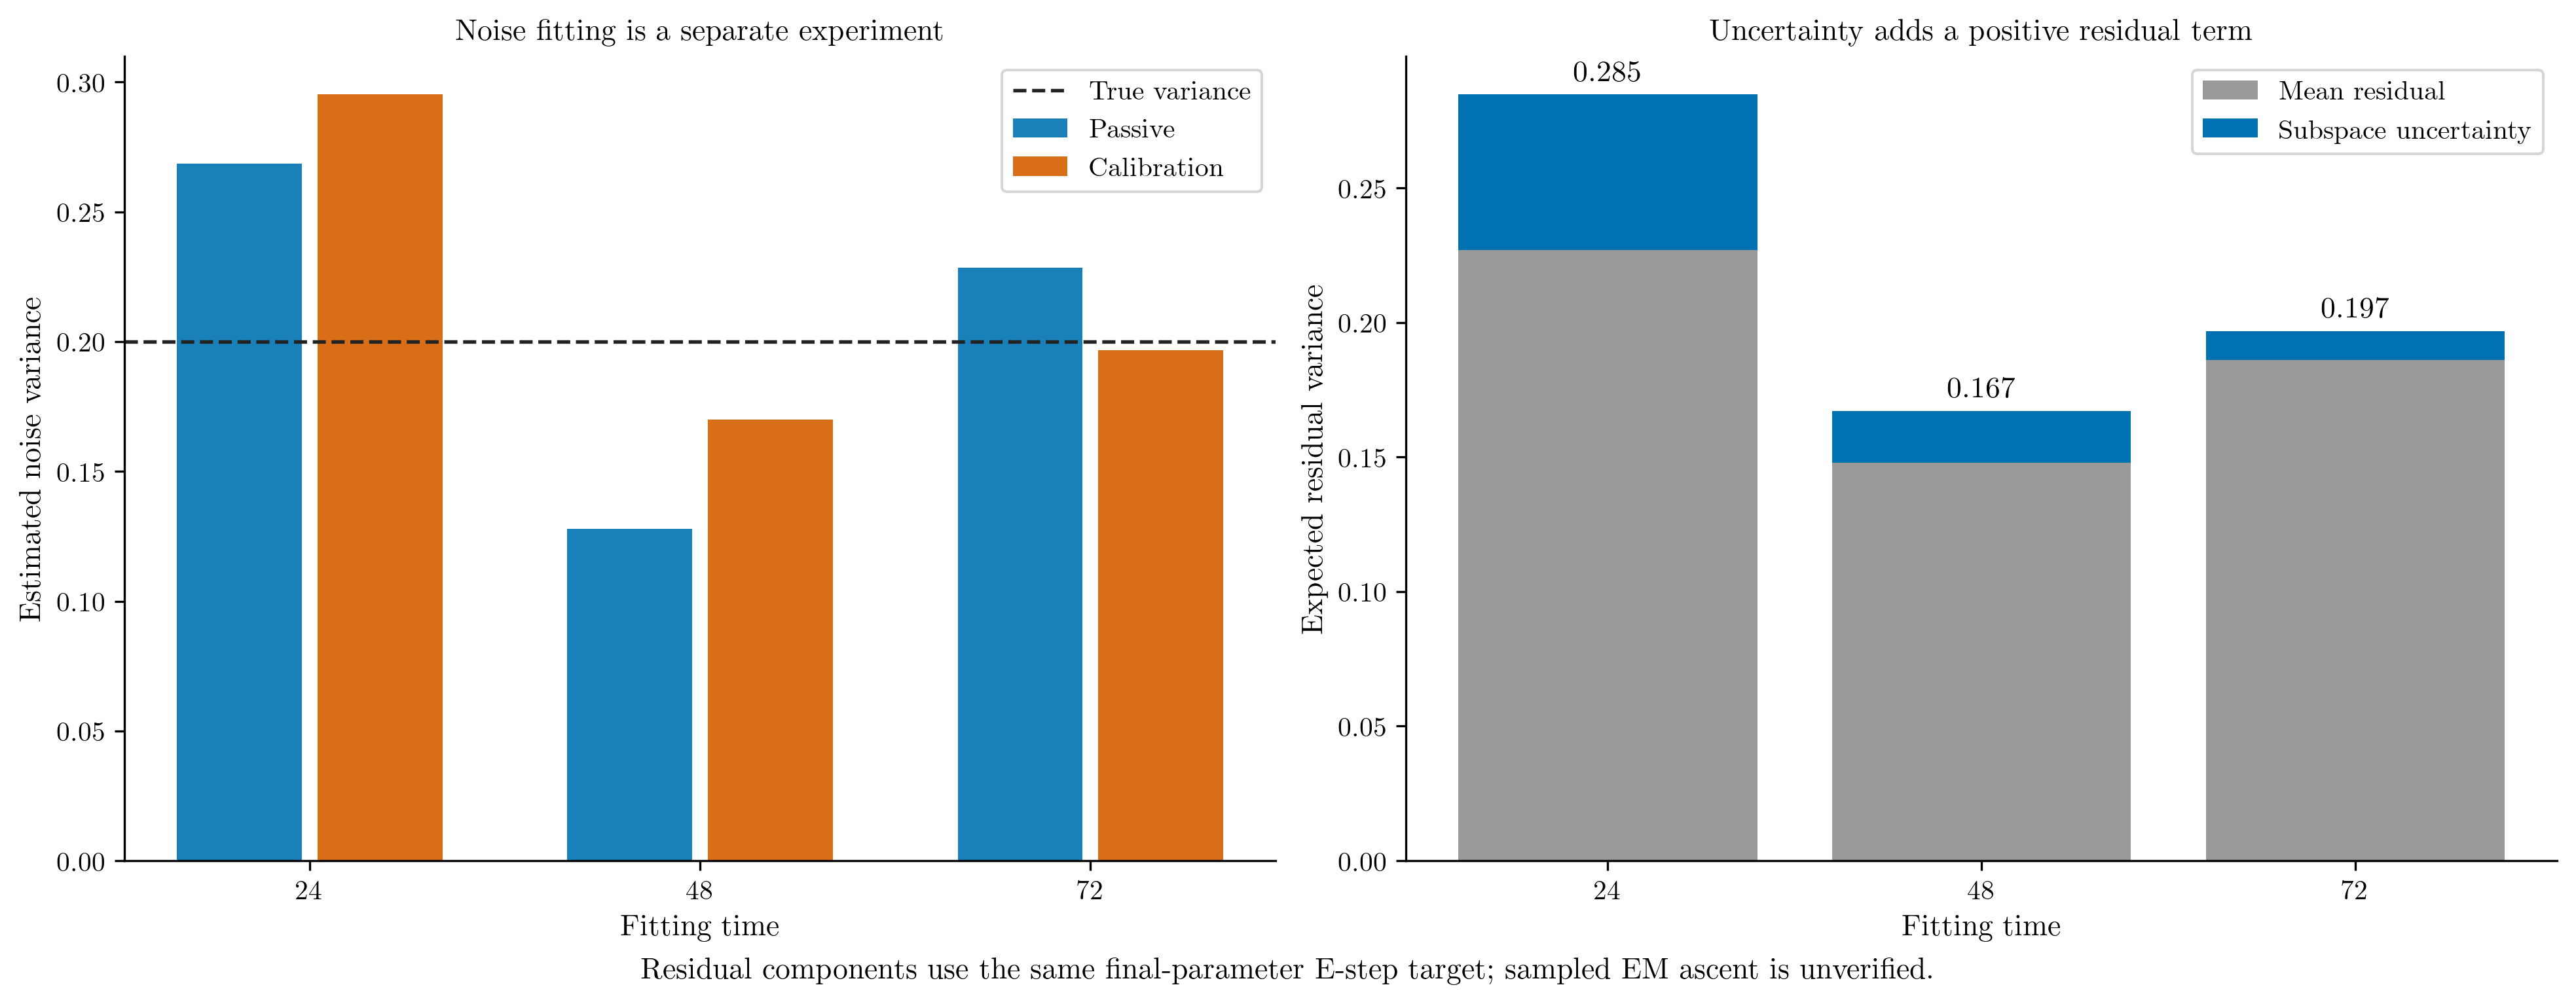

In [19]:
# Saved arrays/tables only; edit the plotting code below freely.
result = load_field_data(ROOT, 'application')

DPI = 300
FIGSIZE = (13, 5)
SAVE_PDF = True

frame = result['noise']
times = sorted(frame.t.unique())
x = np.arange(len(times))
fig, axs = plt.subplots(1, 2, figsize=FIGSIZE, dpi=DPI, layout='constrained')
for protocol, offset, color in [('Passive', -0.18, COLORS['Posterior mean']), ('Calibration', 0.18, COLORS['Mode'])]:
    g = frame[frame.protocol == protocol].set_index('t').reindex(times)
    axs[0].bar(x + offset, g.s, width=0.32, color=color, label=protocol, alpha=0.9)
axs[0].axhline(frame.true_s.iloc[0], color='#222222', ls='--', lw=1.3, label='True variance')
axs[0].set(xticks=x, xticklabels=times, xlabel='Fitting time', ylabel='Estimated noise variance', title='Noise fitting is a separate experiment')
axs[0].legend(fontsize=10)
g = frame[frame.protocol == 'Calibration'].set_index('t').reindex(times)
axs[1].bar(x, g.naive_residual_variance, color='#999999', label='Mean residual')
axs[1].bar(x, g.uncertainty_variance, bottom=g.naive_residual_variance, color=COLORS['Posterior mean'], label='Subspace uncertainty')
for j, value in enumerate(g.expected_residual_variance):
    axs[1].text(j, value + 0.005, f'{value:.3f}', ha='center', fontsize=11)
axs[1].set(xticks=x, xticklabels=times, xlabel='Fitting time', ylabel='Expected residual variance', title='Uncertainty adds a positive residual term')
axs[1].legend(fontsize=10)
fig.supxlabel('Residual components use the same final-parameter E-step target; sampled EM ascent is unverified.', fontsize=11)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_noise.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

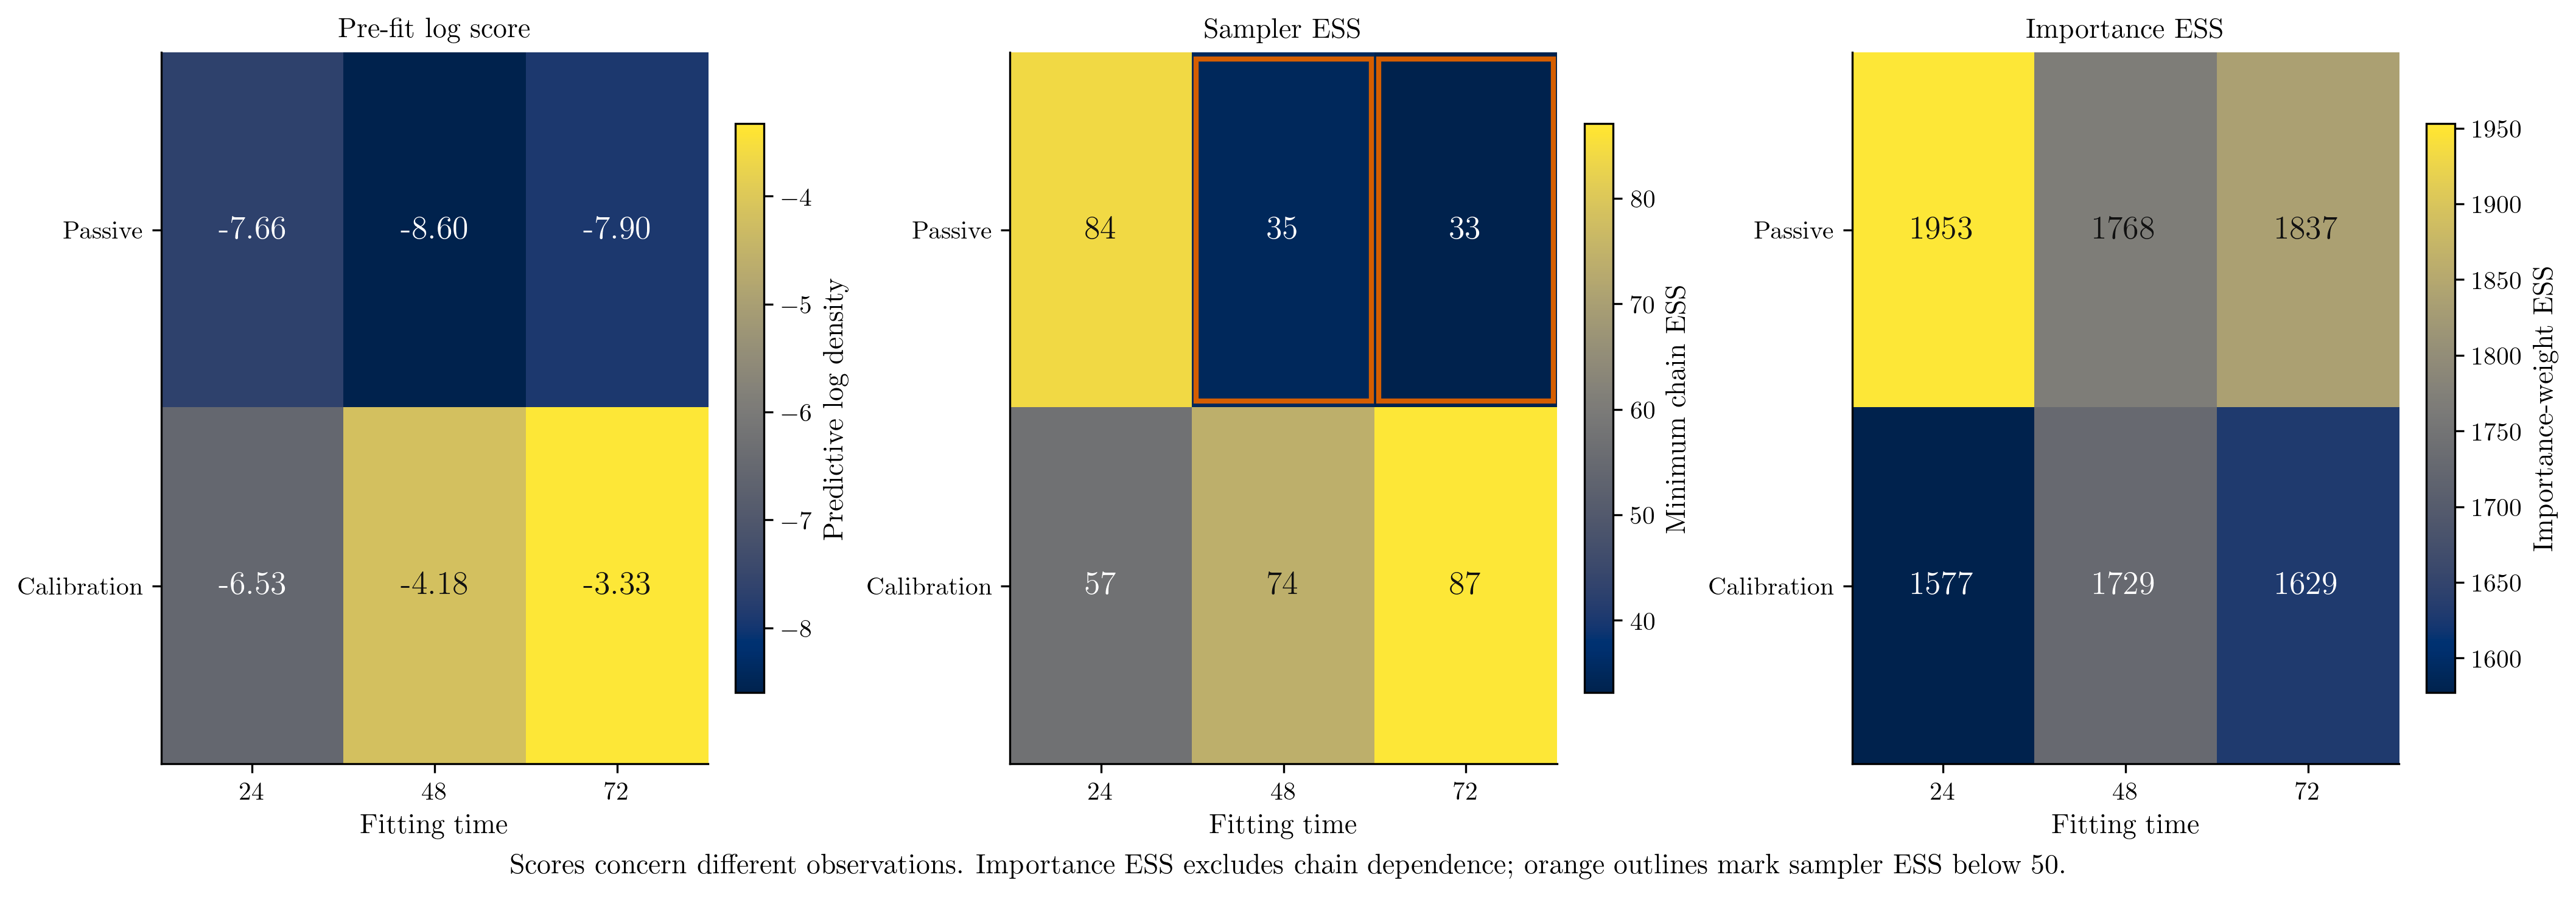

In [20]:
# Saved arrays/tables only; edit the plotting code below freely.
result = load_field_data(ROOT, 'application')

DPI = 300
FIGSIZE = (14, 4.8)
SAVE_PDF = True

frame = result['noise']
protocols = ['Passive', 'Calibration']
times = sorted(frame.t.unique())
fig, axs = plt.subplots(1, 3, figsize=FIGSIZE, dpi=DPI, layout='constrained')
specification = [('predictive_log_score', 'Pre-fit log score', 'Predictive log density', False), ('score_sampler_ess', 'Sampler ESS', 'Minimum chain ESS', True), ('score_importance_ess', 'Importance ESS', 'Importance-weight ESS', True)]
for ax, (column, title, label, is_count) in zip(axs, specification):
    values = frame.pivot(index='protocol', columns='t', values=column).reindex(index=protocols, columns=times)
    array = np.asarray(values, dtype=float)
    image = ax.imshow(array, cmap='cividis', aspect='auto')
    ax.set(xticks=range(len(times)), xticklabels=times, yticks=range(len(protocols)), yticklabels=protocols, xlabel='Fitting time', title=title)
    lo, hi = (float(array.min()), float(array.max()))
    for i in range(len(protocols)):
        for j in range(len(times)):
            color = 'white' if array[i, j] < lo + 0.5 * (hi - lo) else '#111111'
            text = f'{array[i, j]:.0f}' if is_count else f'{array[i, j]:.2f}'
            ax.text(j, i, text, ha='center', va='center', fontsize=13, color=color)
            if column == 'score_sampler_ess' and array[i, j] < 50:
                from matplotlib.patches import Rectangle
                ax.add_patch(Rectangle((j - 0.48, i - 0.48), 0.96, 0.96, fill=False, edgecolor='#D55E00', lw=2))
    fig.colorbar(image, ax=ax, shrink=0.8, label=label)
fig.supxlabel('Scores concern different observations. Importance ESS excludes chain dependence; orange outlines mark sampler ESS below 50.', fontsize=11)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_scores.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

In [21]:
cal=noise[noise.protocol=='Calibration']
assert np.allclose(cal.expected_residual_variance,cal.naive_residual_variance+cal.uncertainty_variance)
display(noise[['protocol','t','score_chain_difference','minimum_ess','numerical_ascent_verified']])

,protocol,t,score_chain_difference,minimum_ess,numerical_ascent_verified
0,Passive,24,0.012346,36.578213,False
1,Passive,48,0.012969,23.719823,False
2,Passive,72,0.019493,21.995372,False
3,Calibration,24,0.038457,22.086918,False
4,Calibration,48,0.071518,26.758641,False
5,Calibration,72,0.027570,27.430202,False


### Decide whether the extra computation is worthwhile
The original implementation spends far more time sampling moments than updating a point estimate. The horizontal axis counts cumulative tracking and moment work through 72 measurements, excluding the final field matrix-vector multiplication. Oracle timing is omitted. The mode also represents the matching EW-PCA control; its duplicate point is not plotted.

If the requirement is only a cheap subspace basis or matched passive reconstruction, these results do not justify the full sampling overhead. Posterior computation is motivated by uncertainty-aware response decisions, directional risk and bounds, or noise diagnostics. It can be requested only when those quantities are needed; faster accurate moment backends remain an implementation opportunity.

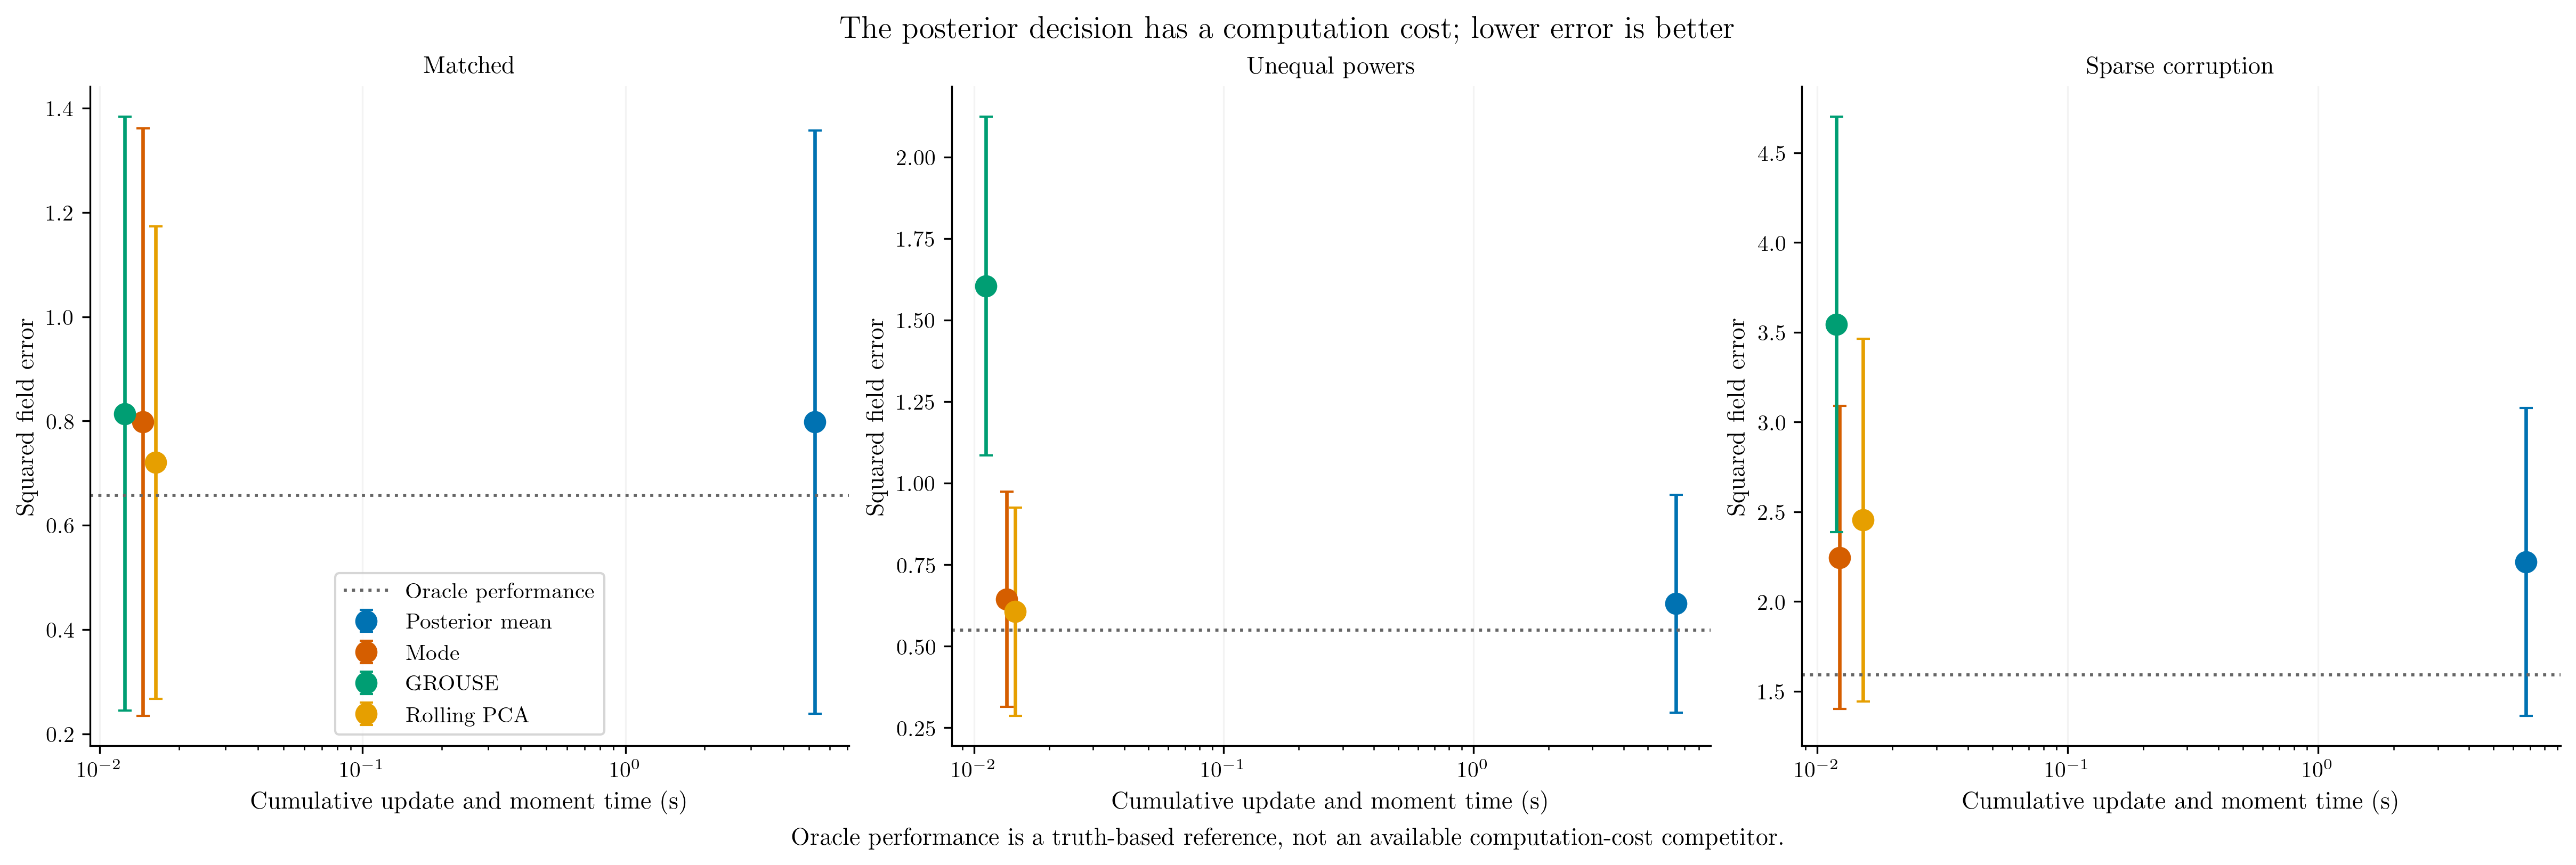

In [22]:
# Saved arrays/tables only; edit the plotting code below freely.
result = load_field_data(ROOT, 'application')
field = True

DPI = 300
FIGSIZE = (16, 5.3)
SAVE_PDF = True

frame = _terminal(result['metrics'])
scenarios = FIELD_SCENARIOS if field else ['Static', 'Drift', 'Contamination']
value = 'field_squared_error' if field else 'sinr_db'
fig, axs = plt.subplots(1, 3, figsize=FIGSIZE, dpi=DPI, layout='constrained')
methods = ['Posterior mean', 'Mode', 'GROUSE', 'Rolling PCA'] if field else ['Posterior mean', 'Mode', 'Loaded covariance']
for ax, scenario in zip(axs, scenarios):
    block = frame[frame.scenario == scenario]
    for method in methods:
        g = block[block.method == method]
        if g.empty:
            continue
        center, low, high = _ci(g[value])
        x = float(g.decision_seconds.mean())
        ax.errorbar(x, center, yerr=[[max(0, center - low)], [max(0, high - center)]], fmt='o', ms=9, capsize=3, color=COLORS[method], label=method)
    oracle = block[block.method == 'Oracle'][value]
    if len(oracle):
        ax.axhline(oracle.mean(), color=COLORS['Oracle'], ls=':', lw=1.4, label='Oracle performance')
    ax.set(xscale='log', xlabel='Cumulative update and moment time (s)', ylabel='Squared field error' if field else 'SINR (dB)', title=scenario)
    ax.grid(axis='x', which='major', alpha=0.15)
axs[0].legend(loc='best', fontsize=10)
suffix = 'lower error is better' if field else 'higher SINR is better'
fig.suptitle(f'The posterior decision has a computation cost; {suffix}', fontsize=14)
fig.supxlabel('Oracle performance is a truth-based reference, not an available computation-cost competitor.', fontsize=11)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_tradeoff.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

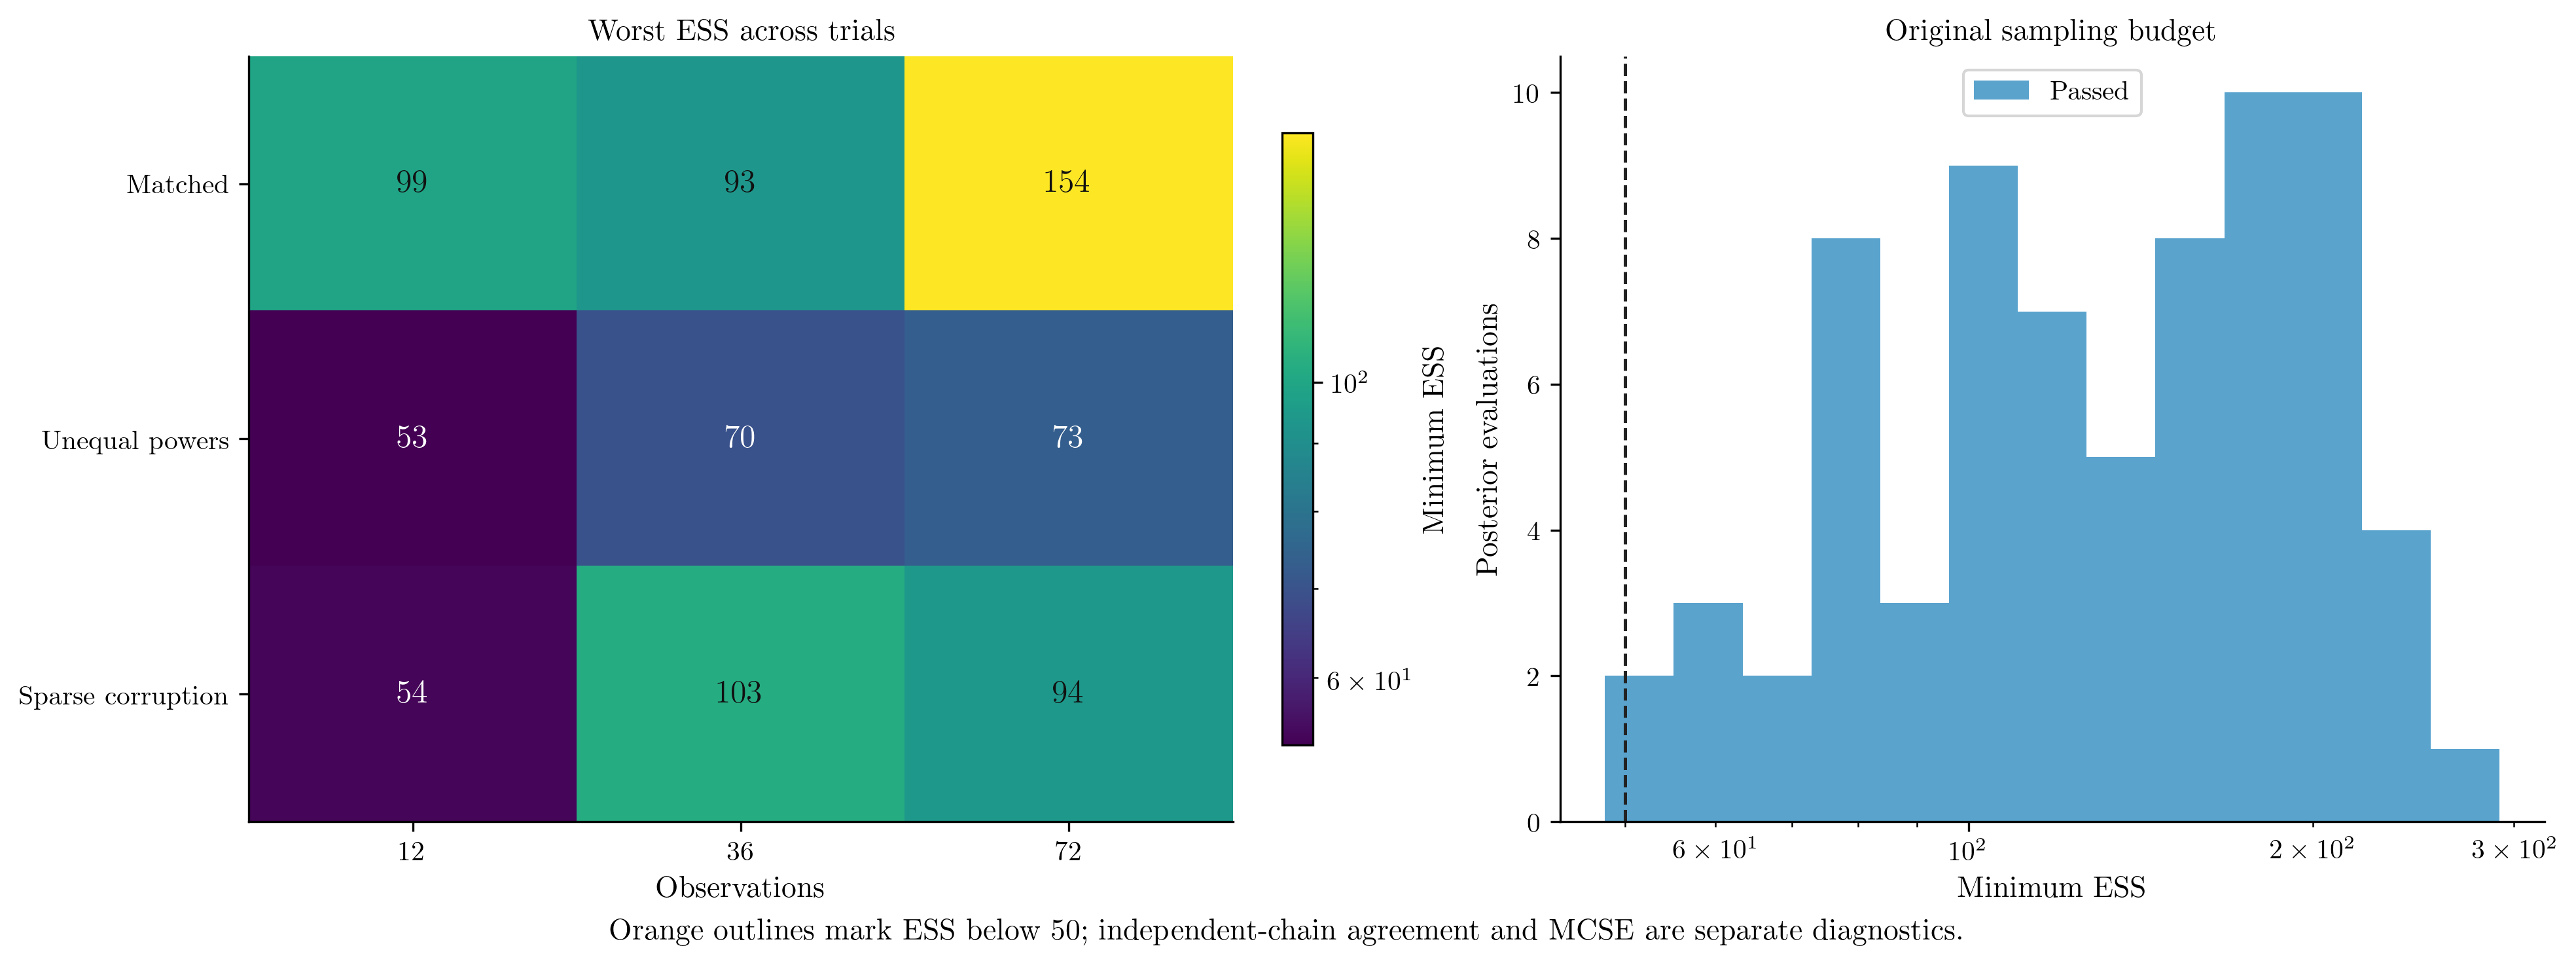

In [23]:
# Saved arrays/tables only; edit the plotting code below freely.
result = load_field_data(ROOT, 'application')
array = False

DPI = 300
FIGSIZE = (13, 6 if array else 4.8)
SAVE_PDF = True

p = result['metrics']
p = p[p.method == 'Posterior mean']
scenarios = [s for s in (ARRAY_SCENARIOS if array else FIELD_SCENARIOS) if s in p.scenario.unique()]
times = sorted(p.t.unique())
values = p.groupby(['scenario', 't']).min_ess.min().unstack('t').reindex(index=scenarios, columns=times)
fig, axs = plt.subplots(1, 2, figsize=FIGSIZE, dpi=DPI, layout='constrained')
v = np.asarray(values)
im = axs[0].imshow(v, cmap='viridis', norm=LogNorm(vmin=max(1, v.min()), vmax=max(51, v.max())), aspect='auto')
for i in range(len(scenarios)):
    for j in range(len(times)):
        axs[0].text(j, i, f'{v[i, j]:.0f}', ha='center', va='center', color='white' if v[i, j] < np.sqrt(v.min() * v.max()) else '#111111', fontsize=12)
        if v[i, j] < 50:
            from matplotlib.patches import Rectangle
            axs[0].add_patch(Rectangle((j - 0.48, i - 0.48), 0.96, 0.96, fill=False, edgecolor='#D55E00', lw=2))
axs[0].set(xticks=range(len(times)), xticklabels=times, yticks=range(len(scenarios)), yticklabels=scenarios, xlabel='Observations', title='Worst ESS across trials')
fig.colorbar(im, ax=axs[0], shrink=0.8, label='Minimum ESS')
for passed, color, label in [(True, COLORS['Posterior mean'], 'Passed'), (False, COLORS['Mode'], 'Capped failure')]:
    g = p[p.sampling_ok.astype(bool) == passed]
    if len(g):
        axs[1].hist(g.min_ess, bins=np.geomspace(max(1, p.min_ess.min() * 0.9), p.min_ess.max() * 1.1, 14), alpha=0.65, color=color, label=label)
axs[1].axvline(50, color='#222222', ls='--', lw=1.2)
axs[1].set(xscale='log', xlabel='Minimum ESS', ylabel='Posterior evaluations', title='Original sampling budget')
axs[1].legend(fontsize=10)
fig.supxlabel('Orange outlines mark ESS below 50; independent-chain agreement and MCSE are separate diagnostics.', fontsize=11)

if SAVE_PDF:
    fig.savefig(EDITABLE_OUTPUT / 'field_accuracy.pdf', dpi=DPI, bbox_inches=None)
plt.show()
plt.close(fig)

In [24]:
p=m[m.method=='Posterior mean']
assert p.sampling_ok.astype(bool).all() and c.sampling_ok.astype(bool).all()
display(m[m.t==m.t.max()].groupby('method')[['decision_seconds','update_seconds']].median())

,decision_seconds,update_seconds
method,,
EW PCA,0.007874,0.007874
GROUSE,0.011537,0.011537
Mode,0.012546,0.012546
Oracle,0.000000,0.000000
Posterior mean,5.302137,0.012546
Rolling PCA,0.015285,0.015285
